# Hybrid weak/strong interpolation with Bayesian model averaging

This notebook jointly averages weak-coupling Fit 4/Fit 11 branches and pole-safe Padé strong-coupling branches after the shared chiral and infinite-volume limits. The ordinary unsplit analyses remain in their fit-specific notebooks.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import copy, gc, json, sys
import time as time_module

REPO_ROOT = Path.cwd().resolve()
while REPO_ROOT != REPO_ROOT.parent and not (REPO_ROOT / 'pyproject.toml').is_file():
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / 'pyproject.toml').is_file():
    raise RuntimeError('Run this notebook from inside the ContinuousBetaFunction repository')
sys.path.insert(0, str(REPO_ROOT / 'src'))

import betafn
import gvar as gv
import lsqfit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from IPython.display import display

print('betafn package:', Path(betafn.__file__).resolve())
print('repository:', REPO_ROOT)

_PROGRESS_START_TIMES = {}
def progress_start(label):
    _PROGRESS_START_TIMES[label] = time_module.monotonic()
    print(f'[START] {label}', flush=True)

def progress_done(label):
    started = _PROGRESS_START_TIMES.pop(label, None)
    elapsed = time_module.monotonic() - started if started is not None else 0.0
    print(f'[DONE] {label} ({elapsed / 60.0:.1f} min)', flush=True)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern'], 'font.size': 15,
    'figure.dpi': 300, 'savefig.dpi': 300,
    'axes.labelsize': 20, 'axes.titlesize': 18,
    'legend.fontsize': 11, 'xtick.labelsize': 18, 'ytick.labelsize': 18,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'grid.alpha': .35, 'grid.linestyle': '-', 'axes.axisbelow': True,
})

betafn package: /Users/yaman/Downloads/ContinuousBetaFunction/src/betafn/__init__.py
repository: /Users/yaman/Downloads/ContinuousBetaFunction


## Configuration and complete window catalogue

Change physics/statistical choices only here. Every downstream cell reads these values.

In [2]:
ANALYSIS_ID = 'hybrid_fit4_fit11_pade_bma'
ANALYSIS_FOOTER = 'hybridBMA'
CORRECTION = 'tln'
DATA_DIR = Path('/Users/yaman/Contbetafn/data/New Four')
HYBRID_OUTPUT_ROOT = REPO_ROOT / 'src/betafn/hybrid_fit4_fit11_pade_bma'
OUTPUT_ROOT = HYBRID_OUTPUT_ROOT
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Strong-coupling ensembles use three finite masses on each of L/a=20, 24, 32.
# This includes the newly available beta_b=7.125 ensembles.
STRONG_COUPLINGS = ('7p00', '7p125', '7p25', '7p50')
WEAK_COUPLINGS = (
    '8p00', '8p50', '9p00', '9p50', '10p0', '11p0',
    '12p0', '14p0', '16p0', '18p0', '20p0',
)
COUPLINGS = STRONG_COUPLINGS + WEAK_COUPLINGS
STRONG_VOLUMES = ('l20l20l20t40', 'l24l24l24t48', 'l32l32l32t64')
VOLUMES = {
    **{coupling: STRONG_VOLUMES for coupling in STRONG_COUPLINGS},
    '8p00': (
        'l32l32l32t64', 'l40l40l40t80', 'l48l48l48t96',
    ),
    **{
        coupling: ('l32l32l32t64', 'l40l40l40t80', 'l48l48l48t96')
        for coupling in WEAK_COUPLINGS if coupling != '8p00'
    },
}
FLOW = 'wilson'
OBSERVABLES = ('p', 'c', 's')
OP_LABELS = {'p': 'Wilson', 'c': 'clover', 's': 'Symanzik'}
# Match the operator convention used in the reference scan notebook.
OP_COLORS = {
    'p': plt.cm.YlOrRd(0.75),
    'c': plt.cm.YlGn(0.75),
    's': plt.cm.Greys(0.75),
}

# Flow-time windows remain an explicit analysis choice. Every selected
# window is analyzed independently; CENTRAL_WINDOW is the primary result.
TMIN_VALUES = tuple(range(5, 6))
TMAX_LIMIT = 6
WINDOWS = tuple(
    (float(tmin), float(tmax))
    for tmin in TMIN_VALUES
    for tmax in range(tmin + 1, TMAX_LIMIT + 1)
)
CENTRAL_WINDOW = (5.0, 6.0)
# Extend through the t0-defining coupling, g_GF^2(t0) ~= 15.79.
# Domain checks in cnt_xtrp still prevent unsupported extrapolation.
G2_GRID = (0.9, 16.0, 0.1)
TARGET_G2 = (1.0, 1.5, 3.0, 5.0, 8.0, 10.0, 12.0, 15.8)
# t0^2 <E(t0)> = 0.3 and g_GF^2 = (16 pi^2 / 3) t^2 <E>.
G2_T0 = (8.0 / 5.0) * np.pi**2

# -------------------------------------------------------------------------
# BMA MODEL SELECTION -- edit only this block to choose included models.
# -------------------------------------------------------------------------
# Each weak family can have its own selected correction orders. Delete a
# family or an order here to exclude it from the BMA.
HYBRID_WEAK_ORDERS_BY_FAMILY = {
    'fit4': (4,),
    'fit11': (4,),
}

# Strong-coupling Pade orders are (numerator order, denominator order).
# Denominator poles are constrained to the negative-z half-line.
HYBRID_PADE_ORDERS = (
    (3, 2),
    (2, 1),
)
# None fits one global matching fraction shared by all flow times and
# operators. The latent N(0,1) prior maps to the uniform interval below.
HYBRID_MATCH_FRACTIONS = (None,)
HYBRID_MATCH_BOUNDS = (0.20, 0.80)
HYBRID_CONTINUITIES = (1,)  # 1 -> C1; use (1, 2) to include C1 and C2

# Leave this as None to use the Cartesian selection above. Alternatively,
# provide an exact list of models, for example:
# HYBRID_EXPLICIT_MODELS = (
#     dict(weak_family='fit4', weak_order=4,
#          numerator_order=1, denominator_order=1,
#          match_fraction=None, continuity=1),
#     dict(weak_family='fit11', weak_order=5,
#          numerator_order=2, denominator_order=1,
#          match_fraction=None, continuity=1),
# )
HYBRID_EXPLICIT_MODELS = None

# Independent candidate models are evaluated in separate processes. Two
# workers is conservative for an interactive laptop run; increase only if
# memory permits. Exact joint covariances and evidences are unchanged.
HYBRID_MAX_WORKERS = 2
HYBRID_CHECKPOINT_ROOT = HYBRID_OUTPUT_ROOT / 'interpolation_checkpoints'

RUN_HYBRID_THINNING = False
HYBRID_THINNING_SPACINGS = (0.10, 0.20, 0.30)
HYBRID_PRIOR_WIDTHS = {
    'weak_width': 5.0,
    'constant_width': 0.25,
    'strong_width': 0.10,
    'pole_log_width': 0.70,
}

def window_tag(window):
    return f't_{window[0]:g}_{window[1]:g}'.replace('.', 'p')

def case_dir(window, mode=None):
    path = OUTPUT_ROOT / window_tag(window)
    if mode is not None:
        path = path / mode
    path.mkdir(parents=True, exist_ok=True)
    return path

def add_fit_footer(fig):
    fig.text(0.995, 0.005, ANALYSIS_FOOTER, ha='right', va='bottom',
             fontsize=8, color='gray', alpha=.75)

def save_figure(fig, window, name, mode=None):
    base = case_dir(window, mode) / name
    add_fit_footer(fig)
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def beta_value(coupling):
    return float(coupling.replace('p', '.'))

def volume_value(volume):
    return np.prod([float(x) for x in volume.replace('t', 'l').split('l')[1:] if x])


def coupling_figure(couplings, ncols=5):
    nrows = max(1, int(np.ceil(len(couplings) / ncols)))
    return plt.subplots(
        nrows, ncols,
        figsize=(4.4 * ncols, 4.2 * nrows),
        squeeze=False,
    )

def pt_over_g4(x, loops):
    x = np.asarray(x, dtype=float)
    pt = bf.perturbative_beta_function
    return sum(-coefficient * x**power / pt.nrm**(power + 1)
               for power, coefficient in enumerate(pt.b[:loops]))

print(f'{len(WINDOWS)} flow-time windows:', WINDOWS)
print('output root:', OUTPUT_ROOT)

1 flow-time windows: ((5.0, 6.0),)
output root: /Users/yaman/Downloads/ContinuousBetaFunction/src/betafn/hybrid_fit4_fit11_pade_bma


## Analysis construction

The pulled upstream package computes TLN on demand. No external `.tln` path is supplied. The raw `Es` history is the rectangle measurement and is replaced by `(5/3)Ep-(2/3)Es` before averaging and TLN.

In [3]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(DATA_DIR)

bf = betafn.BetaFunction(nf=4)

# AnalysisConfig requires an interpolation field for shared stages 1--3.
# The hybrid candidate fits below bypass this placeholder completely.
def _unused_interpolation(x, parameters):
    return np.zeros_like(np.asarray(x, dtype=float))

interpolation = betafn.InterpolationSpec(
    fcn=_unused_interpolation, prior=None, p0={}, xerrors=False,
)

config = betafn.AnalysisConfig(
    data_path=str(DATA_DIR),
    interpolation=interpolation,
    continuum_window=CENTRAL_WINDOW,
    g2_grid=G2_GRID,
    flows=(FLOW,),
    observables=OBSERVABLES,
    combine={'s': {'p': 5.0 / 3.0, 's': -2.0 / 3.0}},
    couplings=COUPLINGS,
    volumes=VOLUMES,
    correction=CORRECTION,
    binsize=1,  # spectral estimator uses the ordered, unbinned history
    covariance_estimator='lugsail',
    bartlett_bandwidth_method='plugin',
    bartlett_window_factor=5.0,
    bartlett_max_fraction=0.25,
    lugsail_r=2.0, lugsail_c=0.5, spectral_psd_adjust=True,
    process_window=(1.5, 10.5),
    fit_window=(2.0, 10.0),
    error_mode='fit',
    cov_mode='empirical',
    correlated=True,
    verbosity=1,  # progress only; does not alter any fit
)
config_summary = config.describe()
config_summary.pop('interpolation_xerrors')
config_summary.pop('interpolation_parameters')
display(pd.DataFrame([config_summary]).T.rename(columns={0: 'hybrid analysis setting'}))

,hybrid analysis setting
data_path,/Users/yaman/Contbetafn/data/New Four
flows,[wilson]
observables,"[p, c, s]"
couplings,"[7p00, 7p125, 7p25, 7p50, 8p00, 8p50, 9p00, 9p..."
volumes,"{'7p00': ['l20l20l20t40', 'l24l24l24t48', 'l32..."
correction,tln
binsize,1
use_gamma_method,False
gamma_window_factor,3.0
covariance_estimator,lugsail


## Stage 1 — processing with TLN

For each ensemble, $\mathbf z_n$ contains every retained flow time and operator measured on configuration $n$. The covariance of the ensemble mean uses the zero-lugsail Bartlett spectral estimator
$$\widehat{\mathrm{Cov}}(\bar{\mathbf z})=\frac{1}{N}\left[\widehat\Gamma(0)+\sum_{k=1}^{M}\left(1-\frac{k}{M+1}\right)\left(\widehat\Gamma(k)+\widehat\Gamma(k)^T\right)\right],$$
and $\widehat\Sigma_L(M)=2\widehat\Sigma_B(M)-\widehat\Sigma_B(\lfloor M/2\rfloor)$. The Liu--Vats--Flegal marginal-AR plug-in rule selects one common $M$ for the complete vector. This preserves correlations across flow times and operators. The table records the bandwidth scan, overlapping-batch-means comparison, and any explicit positive-semidefinite adjustment.

In [4]:
progress_start('processing and covariance estimation')
bf.run_processing(config)
print('correction:', bf._process_config.correction)
print('processed couplings:', sorted(bf.avg_data, key=beta_value))
print('pre-binning: not applied; lugsail Bartlett uses the ordered raw history')
print(bf.data_report())
bartlett_rows = [
    {'coupling': ensemble.coupling, 'volume': ensemble.volume,
     'mass': ensemble.mass, **diagnostics}
    for ensemble, diagnostics in sorted(
        bf.covariance_estimator_diagnostics.items(),
        key=lambda item: item[0].sort_key,
    )
]
BARTLETT_DIAGNOSTICS = pd.DataFrame(bartlett_rows)
BARTLETT_DIAGNOSTICS.to_csv(
    OUTPUT_ROOT / 'bartlett_covariance_diagnostics.csv', index=False
)
display(BARTLETT_DIAGNOSTICS)
progress_done('processing and covariance estimation')

correction: tln
processed couplings: ['7p00', '7p125', '7p25', '7p50', '8p00', '8p50', '9p00', '9p50', '10p0', '11p0', '12p0', '14p0', '16p0', '18p0', '20p0']
pre-binning: not applied; lugsail Bartlett uses the ordered raw history
ensemble                               flow       configs   bins
----------------------------------------------------------------
beta=7 V=20x20x20x40 m=0.001           wilson         277    277
beta=7 V=20x20x20x40 m=0.0025          wilson         200    200
beta=7 V=20x20x20x40 m=0.005           wilson         180    180
beta=7 V=24x24x24x48 m=0.001           wilson          77     77
beta=7 V=24x24x24x48 m=0.0025          wilson          71     71
beta=7 V=24x24x24x48 m=0.005           wilson          81     81
beta=7 V=32x32x32x64 m=0.001           wilson          38     38
beta=7 V=32x32x32x64 m=0.0025          wilson          37     37
beta=7 V=32x32x32x64 m=0.005           wilson          68     68
beta=7.125 V=20x20x20x40 m=0.001       wilson         

,coupling,volume,mass,n_configurations,n_observables,estimator,bandwidth_method,bandwidth,bandwidth_fraction,plugin_unbounded_bandwidth,...,fallback_reason,vanilla_median_se_ratio,obm_batch_size,obm_median_se_ratio,obm_max_abs_log_se_ratio,scan_lower_bandwidth,scan_upper_bandwidth,scan_lower_median_se_ratio,scan_upper_median_se_ratio,scan_max_abs_log_se_ratio
0,7p00,l20l20l20t40,0p001,277,3604,lugsail-bartlett,plugin,19,0.068592,19.495939,...,,0.947536,20,0.960283,0.419177,9,38,1.008561,0.890940,0.406140
1,7p00,l20l20l20t40,0p0025,200,3604,lugsail-bartlett,plugin,20,0.100000,22.881018,...,,0.911135,21,0.953670,0.143568,10,40,0.932130,1.044453,0.626481
2,7p00,l20l20l20t40,0p005,180,3604,lugsail-bartlett,plugin,18,0.100000,18.439756,...,,0.874139,19,0.962201,0.097042,9,36,0.844792,1.120250,0.531095
3,7p00,l24l24l24t48,0p001,77,3604,lugsail-bartlett,plugin,7,0.090909,8.543878,...,,0.873773,8,0.913854,0.176590,3,14,0.830065,1.141801,0.344536
4,7p00,l24l24l24t48,0p0025,71,3604,lugsail-bartlett,plugin,7,0.098592,9.144081,...,,0.888012,8,0.988296,0.189612,3,14,0.890705,1.065981,0.187586
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,18p0,l40l40l40t80,0p00,770,3604,lugsail-bartlett,plugin,9,0.011688,9.396411,...,,0.947028,10,0.956214,0.096913,4,18,0.932277,1.012775,0.188834
65,18p0,l48l48l48t96,0p00,496,3604,lugsail-bartlett,plugin,9,0.018145,9.880161,...,,0.953979,10,0.950220,0.100174,4,18,0.952518,1.101984,0.167598
66,20p0,l32l32l32t64,0p00,484,3604,lugsail-bartlett,plugin,8,0.016529,8.449335,...,,0.922447,9,0.926290,0.079448,4,16,0.901541,1.064363,0.106966
67,20p0,l40l40l40t80,0p00,859,3604,lugsail-bartlett,plugin,12,0.013970,12.727984,...,,0.972088,13,0.977422,0.059988,6,24,0.971257,1.025785,0.157871


## Plot 1 — processed largest-volume data

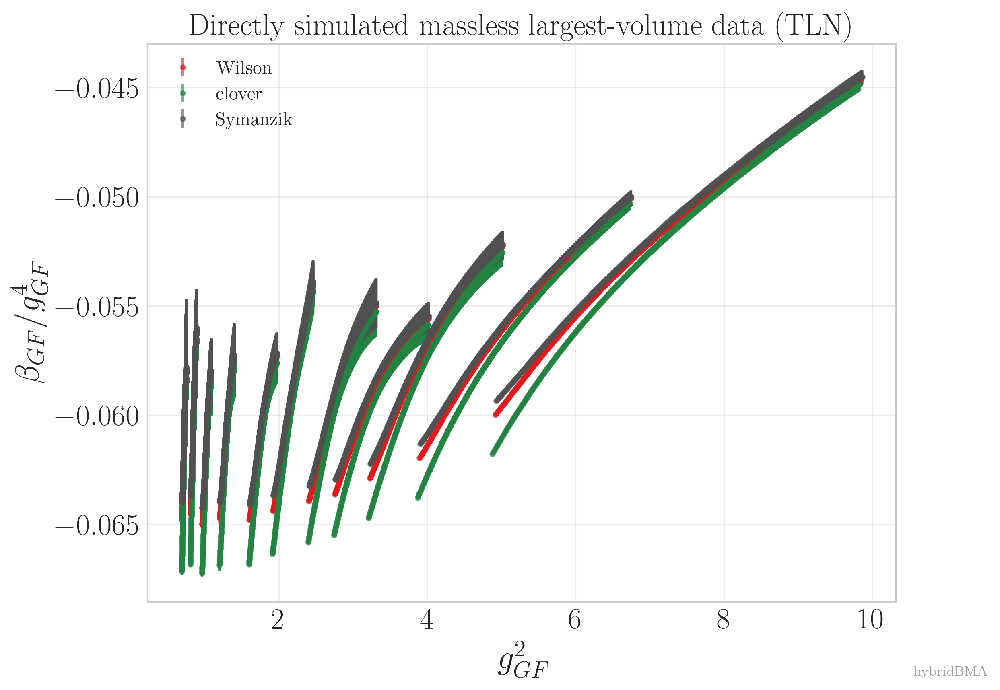

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
for operator in OBSERVABLES:
    first = True
    for coupling in sorted(bf.avg_data, key=beta_value):
        massless_volumes = [
            volume for volume in bf.avg_data[coupling]
            if '0p00' in bf.avg_data[coupling][volume]
        ]
        if not massless_volumes:
            continue
        volume = max(massless_volumes, key=volume_value)
        _, g2 = bf.processed_series(coupling, volume, '0p00', FLOW, operator, 'g2')
        _, beta = bf.processed_series(coupling, volume, '0p00', FLOW, operator, 'beta')
        ratio = np.asarray([b / x**2 for x, b in zip(g2, beta)], dtype=object)
        ax.errorbar(gv.mean(g2), gv.mean(ratio), yerr=gv.sdev(ratio), fmt='o', ms=2.5,
                    alpha=.6, color=OP_COLORS[operator],
                    label=OP_LABELS[operator] if first else None)
        first = False
ax.set(xlabel=r'$g^2_{GF}$', ylabel=r'$\beta_{GF}/g_{GF}^4$', title='Directly simulated massless largest-volume data (TLN)')
ax.legend(frameon=False)
base = OUTPUT_ROOT / f'processed_largest_volume_{ANALYSIS_ID}'
add_fit_footer(fig)
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)

## Pre-interpolation stages — chiral and infinite-volume limits

The chiral and infinite-volume limits are completed before constructing the joint weak/strong candidate models.


In [6]:
progress_start('chiral extrapolation')
bf.run_chiral(config)
progress_done('chiral extrapolation')
progress_start('infinite-volume extrapolation')
bf.run_infinite_volume(config)
progress_done('infinite-volume extrapolation')
print(bf.stage_summary('chiral'))
print(bf.stage_summary('infinite_volume'))

{'stage': 'chiral', 'n_fits': 57672, 'mean_chi2_per_dof': 0.7509774184325916, 'mean_pvalue': 0.5357292894176289}
{'stage': 'infinite_volume', 'n_fits': 72090, 'mean_chi2_per_dof': 2.586749225933916, 'mean_pvalue': 0.3871548078047722}


## Chiral extrapolation diagnostics

For each strong-coupling ensemble, the existing chiral stage fits $g_{\mathrm{GF}}^2$ and $\beta_{\mathrm{GF}}$ separately at fixed $(\beta_b,L/a,t/a^2)$ with the linear form

$$
X(m)=X(0)+k_m m,\qquad X\in\{g_{\mathrm{GF}}^2,\beta_{\mathrm{GF}}\}.
$$

The three simulated masses are used without coefficient priors. The fitted intercept $X(0)$ is inserted as the `0p00` datum before the infinite-volume and interpolation stages. The plots below show the input masses, fitted curves, and massless intercepts for representative flow times; the CSV records every chiral fit. The configured $\beta_b=7.125$ ensembles are picked up automatically when their files are added.


active couplings: ('7p00', '7p125', '7p25', '7p50', '8p00', '8p50', '9p00', '9p50', '10p0', '11p0', '12p0', '14p0', '16p0', '18p0', '20p0')
configured strong couplings without usable data: none


,coupling,beta_b,volume,finite_masses,massless_limit_available,status
0,7p00,7.000,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready
1,7p00,7.000,l24l24l24t48,"0p001, 0p0025, 0p005",True,ready
2,7p00,7.000,l32l32l32t64,"0p001, 0p0025, 0p005",True,ready
3,7p125,7.125,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready
4,7p125,7.125,l24l24l24t48,"0p001, 0p0025, 0p005",True,ready
5,7p125,7.125,l32l32l32t64,"0p001, 0p0025, 0p005",True,ready
6,7p25,7.250,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready
7,7p25,7.250,l24l24l24t48,"0p001, 0p0025, 0p005",True,ready
8,7p25,7.250,l32l32l32t64,"0p001, 0p0025, 0p005",True,ready
9,7p50,7.500,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready


,coupling,beta_b,volume,quantity,operator,flow_time,intercept_mean,intercept_sdev,chi2,dof,p_value
0,7p00,7.0,l20l20l20t40,g2,p,2.00,11.152374,0.029498,0.149637,1,0.698882
1,7p00,7.0,l20l20l20t40,g2,p,2.01,11.179928,0.029771,0.150752,1,0.697818
2,7p00,7.0,l20l20l20t40,g2,p,2.02,11.207443,0.030045,0.151872,1,0.696753
3,7p00,7.0,l20l20l20t40,g2,p,2.03,11.234920,0.030320,0.152997,1,0.695688
4,7p00,7.0,l20l20l20t40,g2,p,2.04,11.262358,0.030596,0.154127,1,0.694623
...,...,...,...,...,...,...,...,...,...,...,...
57667,7p50,7.5,l32l32l32t64,beta,s,9.96,-9.684750,0.276112,5.966482,1,0.014580
57668,7p50,7.5,l32l32l32t64,beta,s,9.97,-9.693480,0.276540,5.968743,1,0.014562
57669,7p50,7.5,l32l32l32t64,beta,s,9.98,-9.702211,0.276968,5.970999,1,0.014543
57670,7p50,7.5,l32l32l32t64,beta,s,9.99,-9.710941,0.277397,5.973249,1,0.014524


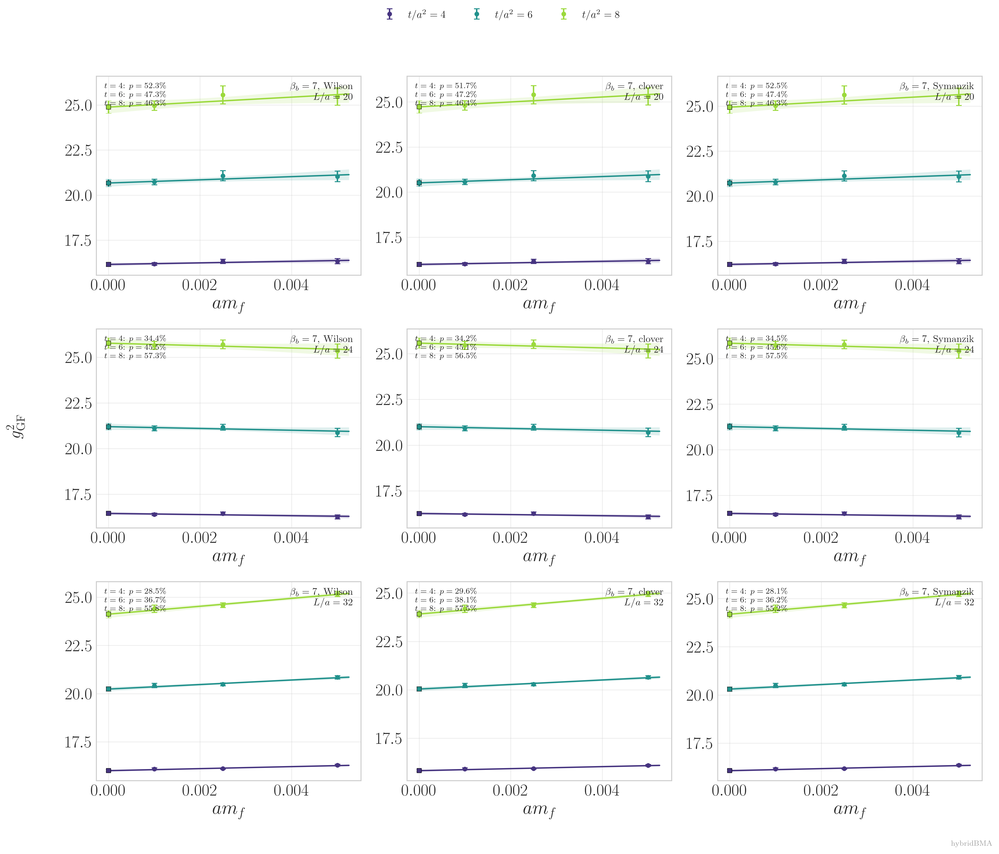

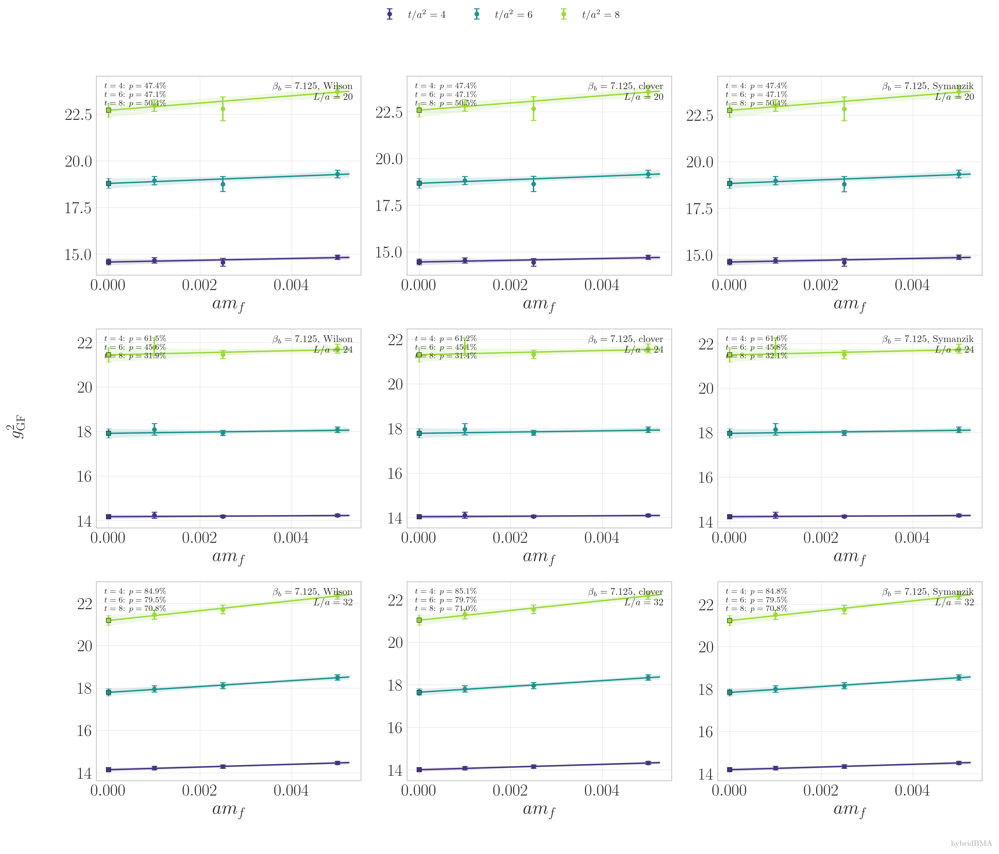

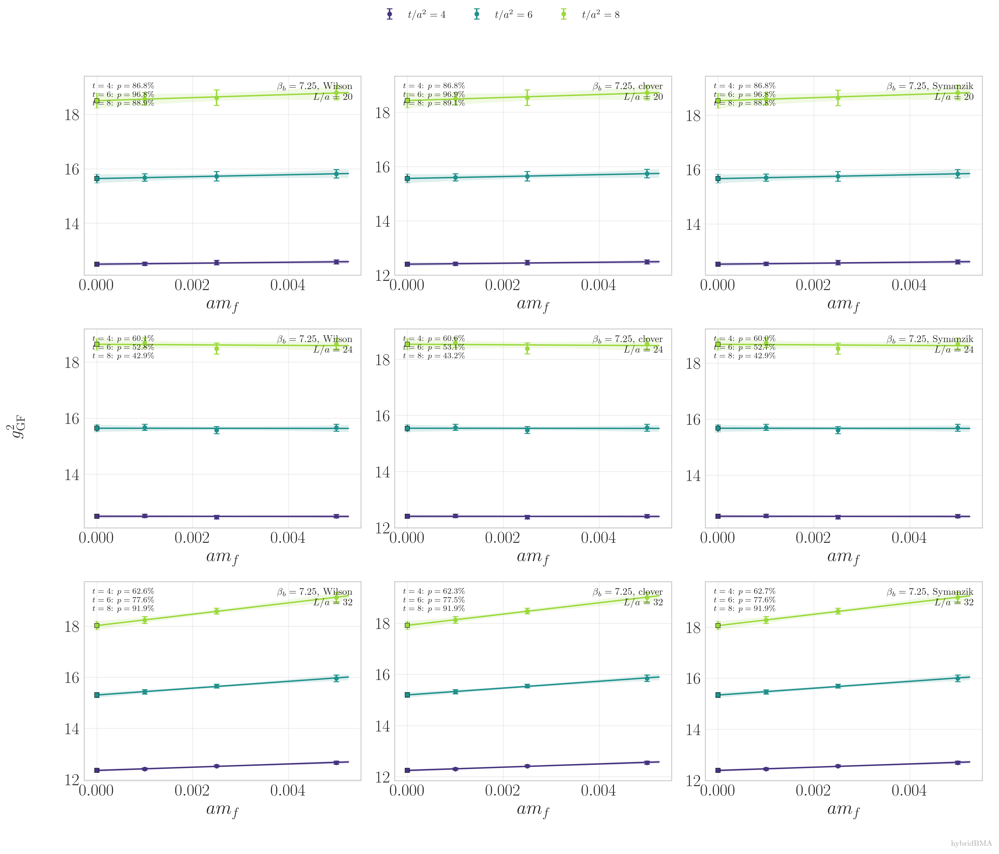

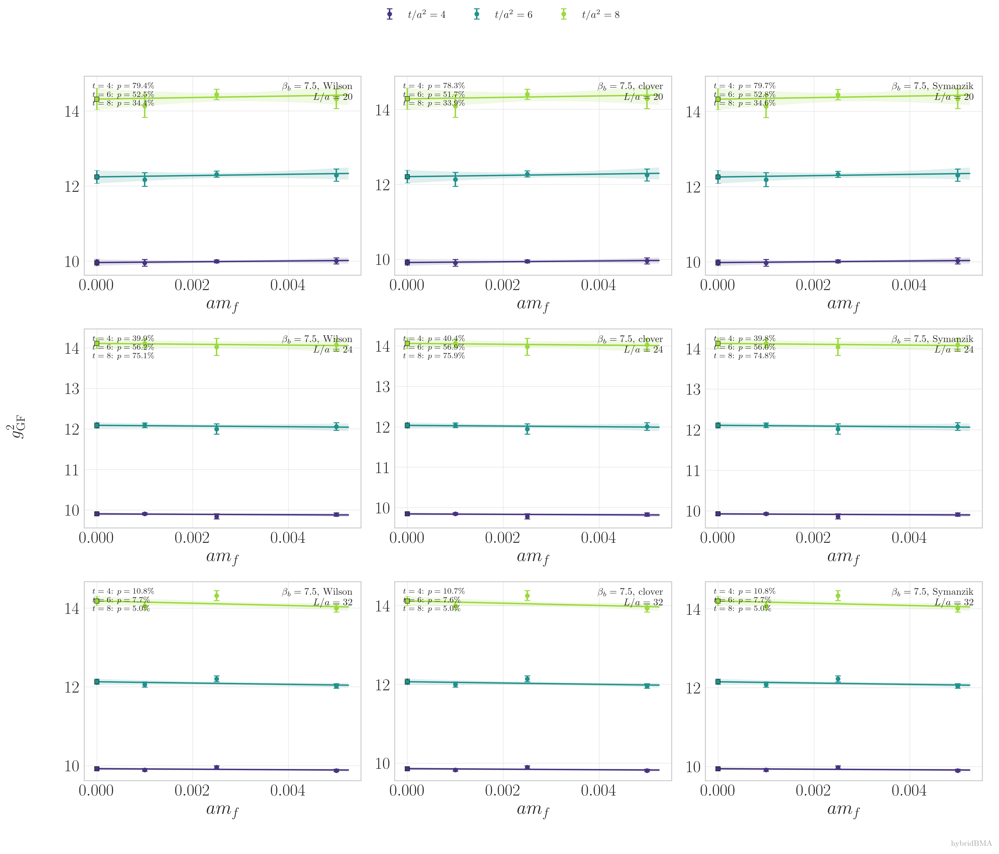

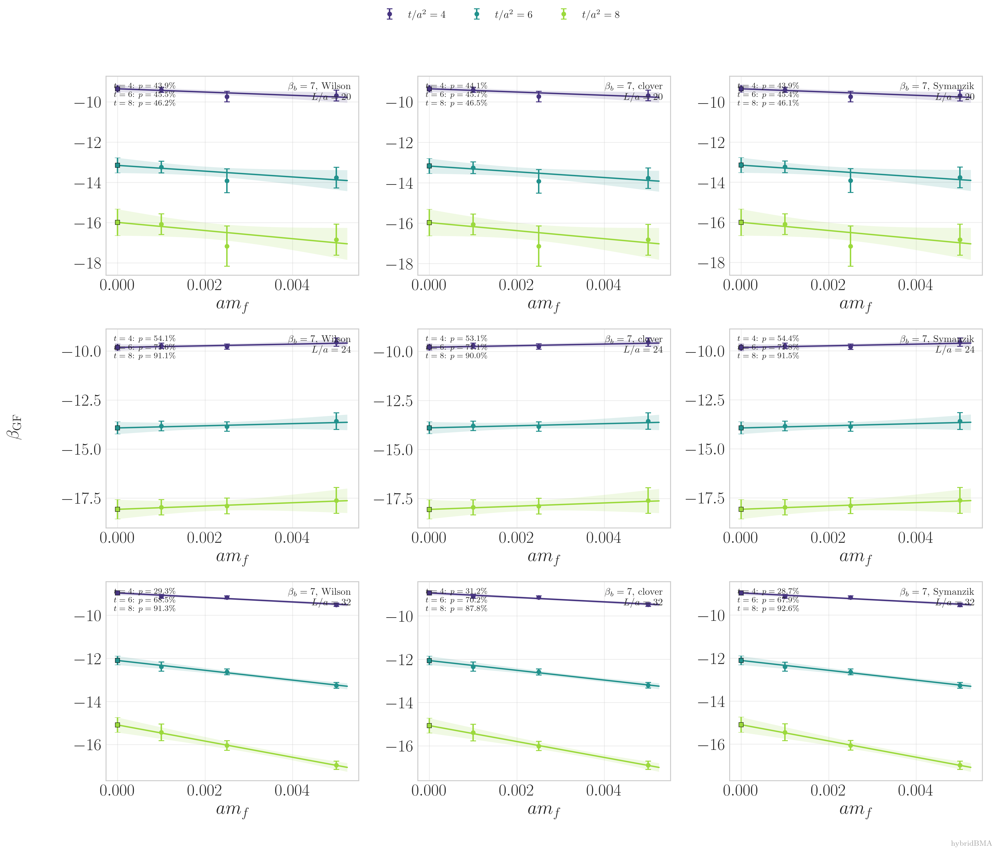

...

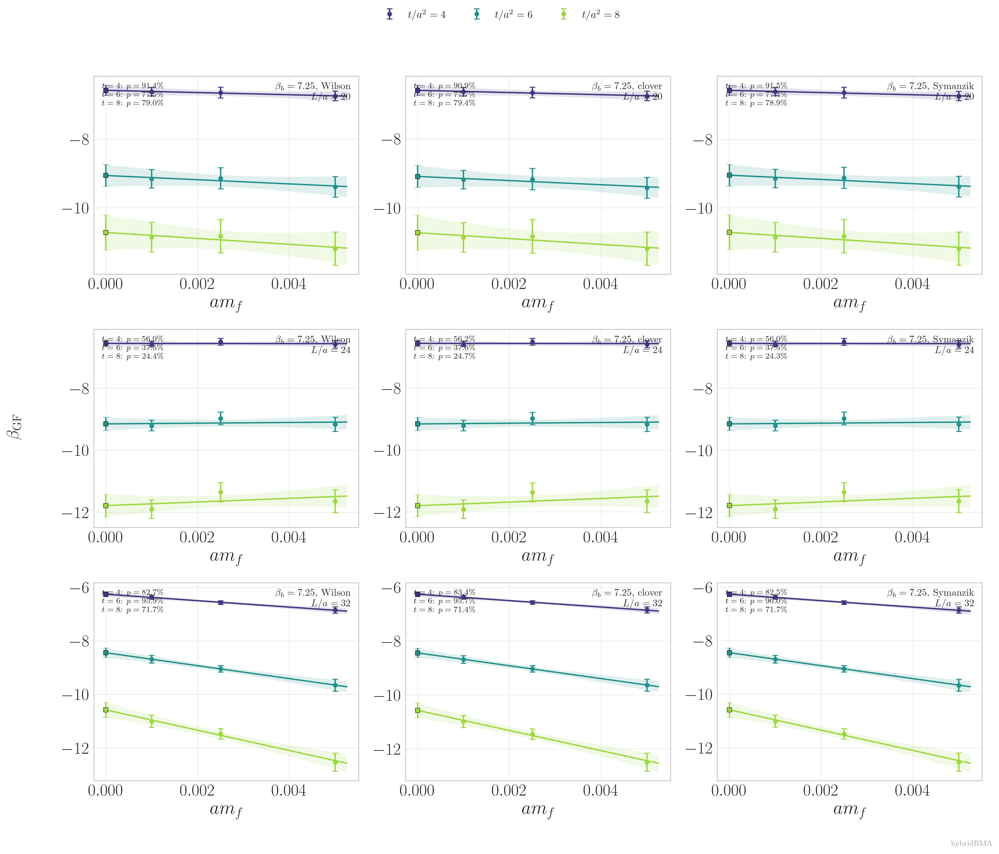

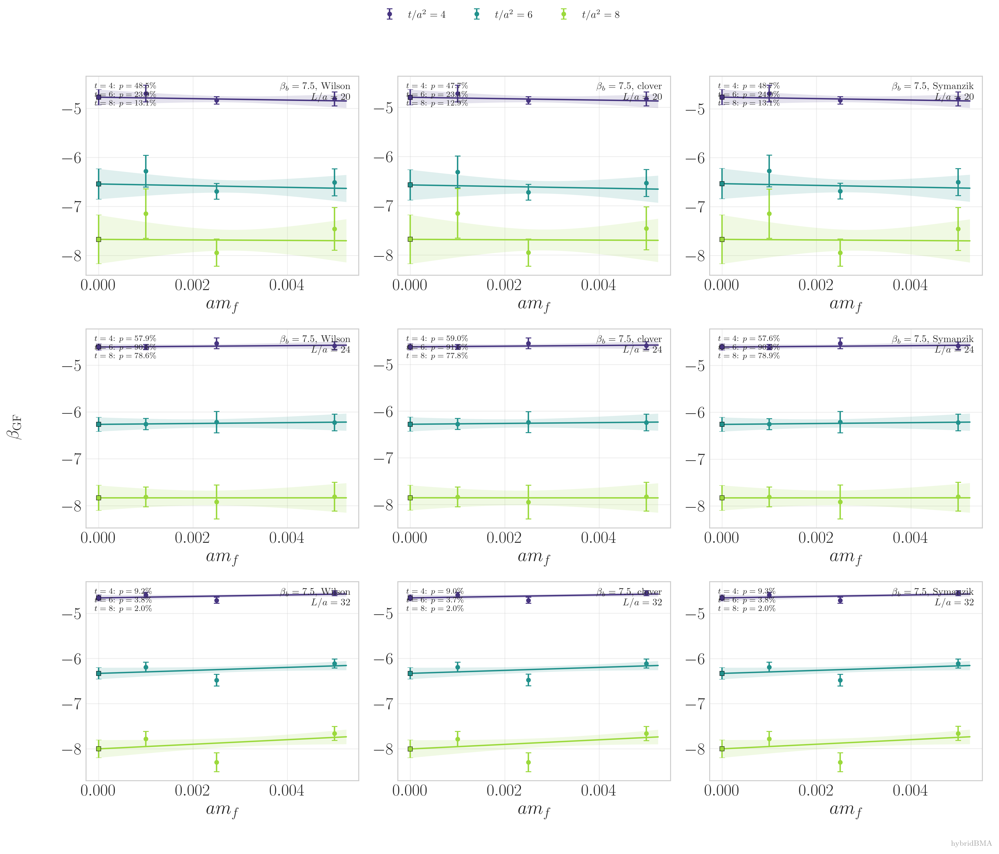

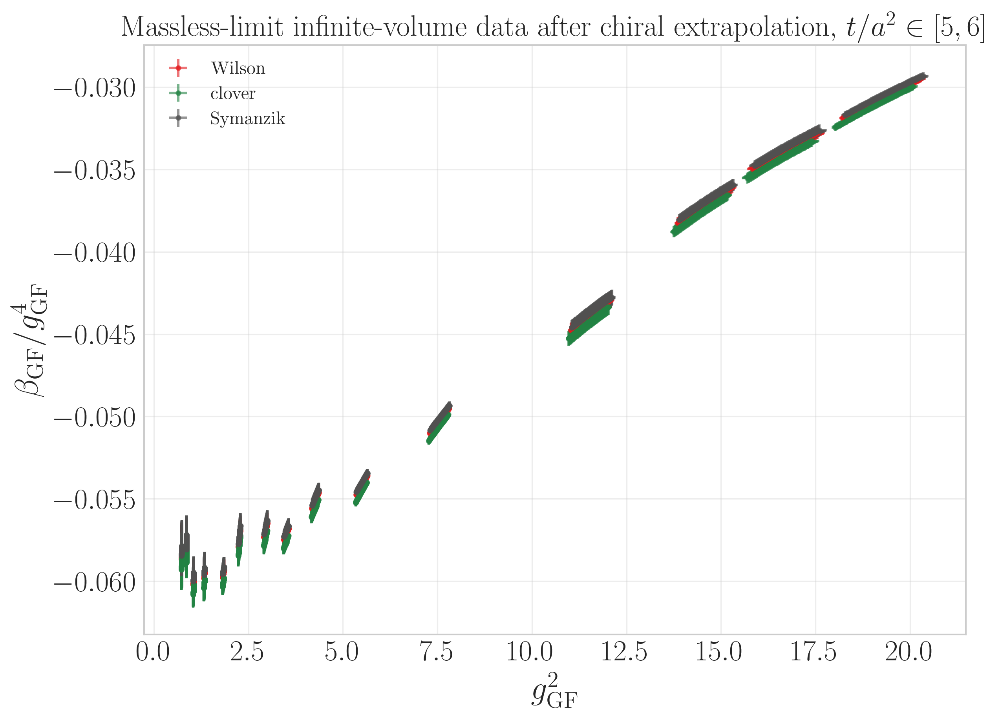

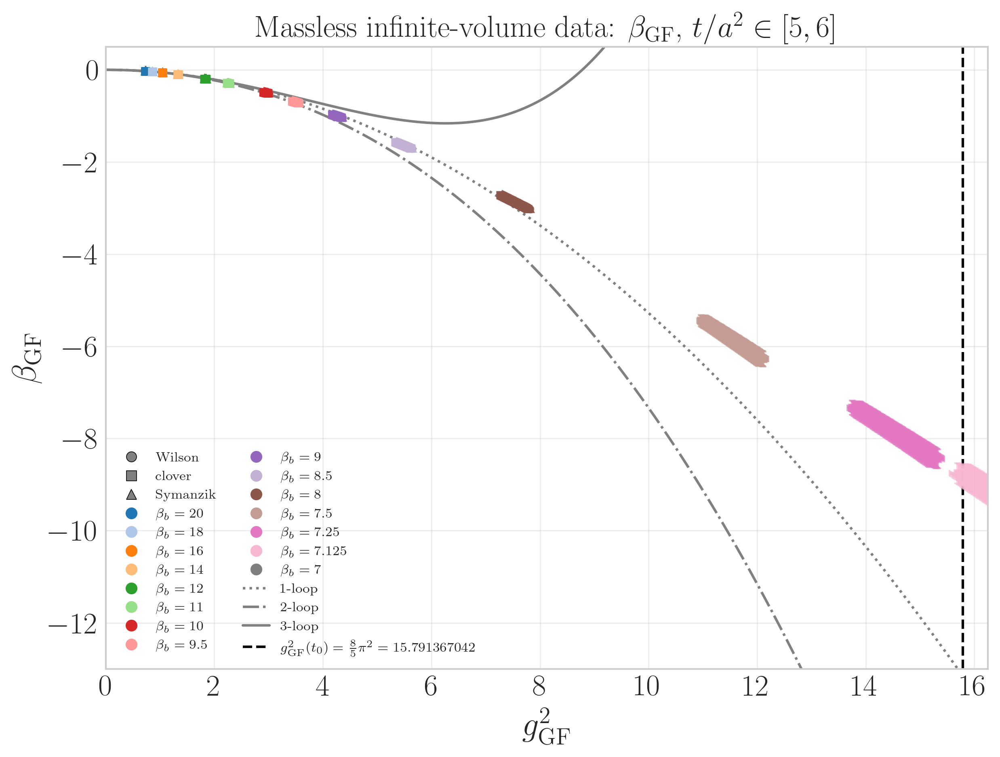

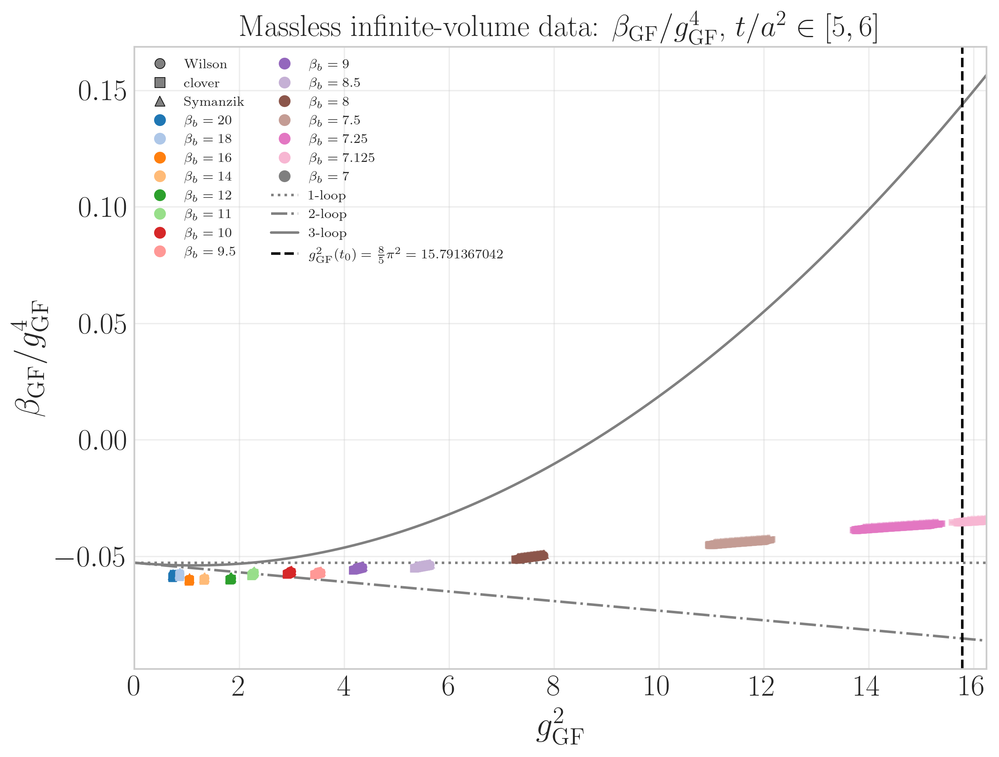

/var/folders/20/xv2dtgc13bn39rbld0pnw18h0000gn/T/ipykernel_80620/3103988092.py:112: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')


In [7]:
ACTIVE_COUPLINGS = tuple(sorted(bf.avg_data, key=beta_value))
ACTIVE_STRONG_COUPLINGS = tuple(
    coupling for coupling in STRONG_COUPLINGS if coupling in bf.avg_data
)
MISSING_STRONG_COUPLINGS = tuple(
    coupling for coupling in STRONG_COUPLINGS if coupling not in bf.avg_data
)
IV_COUPLINGS = tuple(
    coupling for coupling in ACTIVE_COUPLINGS
    if coupling in bf.iv_fits
    and any(bf.iv_fits[coupling]['g2'][FLOW][operator]
            for operator in OBSERVABLES)
)

print('active couplings:', ACTIVE_COUPLINGS)
print('configured strong couplings without usable data:', MISSING_STRONG_COUPLINGS or 'none')

EXPECTED_CHIRAL_MASSES = ('0p001', '0p0025', '0p005')
inventory_rows = []
for coupling in STRONG_COUPLINGS:
    if coupling not in bf.avg_data:
        inventory_rows.append({
            'coupling': coupling,
            'beta_b': beta_value(coupling),
            'volume': 'all configured volumes',
            'finite_masses': '',
            'massless_limit_available': False,
            'status': 'awaiting files',
        })
        continue
    for volume in VOLUMES[coupling]:
        volume_data = bf.avg_data[coupling].get(volume, {})
        finite_masses = sorted(
            (mass for mass in volume_data if mass != '0p00'),
            key=lambda mass: float(mass.replace('p', '.')),
        )
        inventory_rows.append({
            'coupling': coupling,
            'beta_b': beta_value(coupling),
            'volume': volume,
            'finite_masses': ', '.join(finite_masses),
            'massless_limit_available': '0p00' in volume_data,
            'status': (
                'ready'
                if tuple(finite_masses) == EXPECTED_CHIRAL_MASSES
                else 'incomplete mass set'
            ),
        })

chiral_inventory = pd.DataFrame(inventory_rows)
chiral_inventory.to_csv(OUTPUT_ROOT / 'chiral_ensemble_inventory.csv', index=False)
display(chiral_inventory)

chiral_quality_rows = []
for coupling in ACTIVE_STRONG_COUPLINGS:
    for volume in VOLUMES[coupling]:
        if volume not in bf.ch_fits.get(coupling, {}):
            continue
        for quantity in ('g2', 'beta'):
            for operator in OBSERVABLES:
                fits = bf.ch_fits[coupling][volume][quantity][FLOW][operator]
                qualities = bf.ch_qof[coupling][volume][quantity][FLOW][operator]
                for time, params in fits.items():
                    qof = qualities[time]
                    intercept = bf.chiral.model.evaluate(0.0, params)
                    chiral_quality_rows.append({
                        'coupling': coupling,
                        'beta_b': beta_value(coupling),
                        'volume': volume,
                        'quantity': quantity,
                        'operator': operator,
                        'flow_time': float(time),
                        'intercept_mean': float(gv.mean(intercept)),
                        'intercept_sdev': float(gv.sdev(intercept)),
                        'chi2': float(qof['chi2']),
                        'dof': int(qof['dof']),
                        'p_value': float(qof['p-value']),
                    })

chiral_fit_quality = pd.DataFrame(chiral_quality_rows)
chiral_fit_quality.to_csv(
    OUTPUT_ROOT / 'chiral_fit_quality_summary.csv', index=False
)
display(chiral_fit_quality)

CHIRAL_PLOT_TIMES = (4.0, 6.0, 8.0)
CHIRAL_TIME_COLORS = dict(zip(
    CHIRAL_PLOT_TIMES,
    plt.cm.viridis(np.linspace(0.15, 0.85, len(CHIRAL_PLOT_TIMES))),
))

def plot_chiral_extrapolations(quantity):
    ylabel = (
        r'$g^2_{\mathrm{GF}}$'
        if quantity == 'g2'
        else r'$\beta_{\mathrm{GF}}$'
    )
    for coupling in ACTIVE_STRONG_COUPLINGS:
        volumes = [
            volume for volume in VOLUMES[coupling]
            if volume in bf.ch_fits.get(coupling, {})
            and any(
                bf.ch_fits[coupling][volume]['g2'][FLOW][operator]
                for operator in OBSERVABLES
            )
        ]
        if not volumes:
            continue
        fig, axes = plt.subplots(
            len(volumes), len(OBSERVABLES),
            figsize=(15, 4.2 * len(volumes)),
            squeeze=False,
        )
        for row, volume in enumerate(volumes):
            for column, operator in enumerate(OBSERVABLES):
                ax = axes[row, column]
                available = sorted(
                    bf.ch_fits[coupling][volume][quantity][FLOW][operator],
                    key=float,
                )
                selected = []
                selected_times = set()
                for target in CHIRAL_PLOT_TIMES:
                    if not available:
                        continue
                    time = min(available, key=lambda value: abs(float(value) - target))
                    if time not in selected_times:
                        selected.append((target, time))
                        selected_times.add(time)

                pvalue_lines = []
                for target, time in selected:
                    data = bf.chiral.fetch(
                        'inputs', (coupling, volume, quantity, FLOW, operator, time)
                    )
                    params = bf.chiral.fetch(
                        'fits', (coupling, volume, quantity, FLOW, operator, time)
                    )
                    qof = bf.chiral.fetch(
                        'quality', (coupling, volume, quantity, FLOW, operator, time)
                    )
                    masses = np.asarray(data.x, dtype=float)
                    values = np.asarray(data.y, dtype=object)
                    mass_grid = np.linspace(0.0, 1.05 * masses.max(), 160)
                    curve = np.asarray([
                        bf.chiral.model.evaluate(mass, params)
                        for mass in mass_grid
                    ], dtype=object)
                    intercept = bf.chiral.model.evaluate(0.0, params)
                    color = CHIRAL_TIME_COLORS[target]
                    label = rf'$t/a^2={float(time):g}$'
                    ax.errorbar(
                        masses, gv.mean(values), yerr=gv.sdev(values),
                        fmt='o', ms=4, capsize=3, color=color, label=label,
                    )
                    ax.plot(mass_grid, gv.mean(curve), color=color, lw=1.5)
                    ax.fill_between(
                        mass_grid,
                        gv.mean(curve) - gv.sdev(curve),
                        gv.mean(curve) + gv.sdev(curve),
                        color=color, alpha=.14, linewidth=0,
                    )
                    ax.errorbar(
                        [0.0], [gv.mean(intercept)], yerr=[gv.sdev(intercept)],
                        fmt='s', ms=5, capsize=3, color=color,
                        markeredgecolor='black', markeredgewidth=.4,
                    )
                    pvalue_lines.append(
                        rf'$t={float(time):g}$: $p={100.0 * float(qof["p-value"]):.1f}\%$'
                    )

                spatial_extent = int(volume.split('l')[1])
                ax.set_xlabel(r'$am_f$')
                ax.text(
                    .97, .97,
                    rf'$\beta_b={beta_value(coupling):g}$, ' + OP_LABELS[operator]
                    + '\n' + rf'$L/a={spatial_extent}$',
                    transform=ax.transAxes, ha='right', va='top', fontsize=10.5,
                )
                ax.text(
                    .03, .97, '\n'.join(pvalue_lines), transform=ax.transAxes,
                    ha='left', va='top', fontsize=8.5,
                )

        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=max(1, len(handles)), loc='upper center', frameon=False)
        fig.supylabel(ylabel)
        fig.tight_layout(rect=(.03, .02, 1, .93))
        base = OUTPUT_ROOT / f'chiral_extrapolation_{quantity}_{coupling}_{ANALYSIS_ID}'
        add_fit_footer(fig)
        fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
        fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close(fig)

plot_chiral_extrapolations('g2')
plot_chiral_extrapolations('beta')

# Confirm that the massless data used downstream are mutually consistent
# after the infinite-volume extrapolation. Keep each flow-time window
# separate so the plotted sample matches that window.
def plot_processed_massless_infinite_volume(window):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for operator in OBSERVABLES:
        first = True
        for coupling in sorted(IV_COUPLINGS, key=beta_value, reverse=True):
            g2_fits = bf.iv_fits[coupling]['g2'][FLOW][operator]
            beta_fits = bf.iv_fits[coupling]['beta'][FLOW][operator]
            common_times = [
                flow_time
                for flow_time in sorted(set(g2_fits) & set(beta_fits), key=float)
                if window[0] <= float(flow_time) <= window[1]
            ]
            for flow_time in common_times:
                g2_iv = bf.infinite_volume.model.evaluate(
                    0.0, g2_fits[flow_time]
                )
                beta_iv = bf.infinite_volume.model.evaluate(
                    0.0, beta_fits[flow_time]
                )
                ratio_iv = beta_iv / g2_iv**2
                ax.errorbar(
                    gv.mean(g2_iv), gv.mean(ratio_iv),
                    xerr=gv.sdev(g2_iv), yerr=gv.sdev(ratio_iv),
                    fmt='o', ms=2.5, alpha=.6,
                    color=OP_COLORS[operator],
                    label=OP_LABELS[operator] if first else None,
                )
                first = False
    ax.set(
        xlabel=r'$g^2_{\mathrm{GF}}$',
        ylabel=r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$',
        title=(
            'Massless-limit infinite-volume data after chiral extrapolation, '
            rf'$t/a^2\in[{window[0]:g},{window[1]:g}]$'
        ),
    )
    ax.legend(frameon=False)
    plt.show()
    save_figure(
        fig, window,
        f'processed_massless_limit_infinite_volume_{ANALYSIS_ID}',
    )


for window in WINDOWS:
    plot_processed_massless_infinite_volume(window)


# Raw massless infinite-volume intercepts before interpolation.
ordered_iv_couplings = tuple(
    sorted(IV_COUPLINGS, key=beta_value, reverse=True)
)
qualitative_colors = tuple(plt.get_cmap('tab20').colors)
beta_colors = {
    coupling: qualitative_colors[index % len(qualitative_colors)]
    for index, coupling in enumerate(ordered_iv_couplings)
}
operator_markers = {'p': 'o', 'c': 's', 's': '^'}
plot_xmax = max(G2_GRID[1], G2_T0) + 0.25
xp_pt = np.linspace(0.001, plot_xmax, 900)
pt_styles = (
    (1, ':', '1-loop'),
    (2, '-.', '2-loop'),
    (3, '-', '3-loop'),
)
operator_handles = [
    Line2D(
        [0], [0], marker=operator_markers[operator], linestyle='none',
        color='gray', markeredgecolor='black', markeredgewidth=.4,
        label=OP_LABELS[operator],
    )
    for operator in OBSERVABLES
]
coupling_handles = [
    Line2D(
        [0], [0], marker='o', linestyle='none',
        color=beta_colors[coupling], markersize=6,
        label=rf'$\beta_b={beta_value(coupling):g}$',
    )
    for coupling in ordered_iv_couplings
]
pt_handles = [
    Line2D(
        [0], [0], color='gray', linestyle=linestyle,
        lw=1.5, label=label,
    )
    for _, linestyle, label in pt_styles
]
t0_handle = Line2D(
    [0], [0], color='black', linestyle='--', lw=1.5,
    label=rf'$g^2_{{\mathrm{{GF}}}}(t_0)=\frac{{8}}{{5}}\pi^2={G2_T0:.9f}$',
)


def plot_massless_infinite_volume(window, divide_by_g4=False):
    """Plot massless IV data using only flow times inside one window."""
    fig, ax = plt.subplots(figsize=(8.5, 6.5))

    for coupling in ordered_iv_couplings:
        color = beta_colors[coupling]
        for operator in OBSERVABLES:
            g2_fits = bf.iv_fits[coupling]['g2'][FLOW][operator]
            beta_fits = bf.iv_fits[coupling]['beta'][FLOW][operator]
            common_times = [
                flow_time
                for flow_time in sorted(set(g2_fits) & set(beta_fits), key=float)
                if window[0] <= float(flow_time) <= window[1]
            ]
            for flow_time in common_times:
                g2_iv = bf.infinite_volume.model.evaluate(
                    0.0, g2_fits[flow_time]
                )
                beta_iv = bf.infinite_volume.model.evaluate(
                    0.0, beta_fits[flow_time]
                )
                value = beta_iv / g2_iv**2 if divide_by_g4 else beta_iv
                ax.errorbar(
                    gv.mean(g2_iv), gv.mean(value),
                    xerr=gv.sdev(g2_iv), yerr=gv.sdev(value),
                    fmt=operator_markers[operator], ms=3.8, capsize=2,
                    color=color, alpha=.58, linestyle='none',
                )

    for loops, linestyle, _ in pt_styles:
        ratio_pt = pt_over_g4(xp_pt, loops)
        perturbative_value = ratio_pt if divide_by_g4 else xp_pt**2 * ratio_pt
        ax.plot(
            xp_pt, perturbative_value,
            color='gray', ls=linestyle, lw=1.5, zorder=1,
        )

    quantity = (
        r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$'
        if divide_by_g4 else r'$\beta_{\mathrm{GF}}$'
    )
    ax.set(
        xlim=(0.0, plot_xmax),
        xlabel=r'$g^2_{\mathrm{GF}}$',
        ylabel=quantity,
        title=(
            rf'Massless infinite-volume data: {quantity}, '
            rf'$t/a^2\in[{window[0]:g},{window[1]:g}]$'
        ),
    )
    if not divide_by_g4:
        ax.set_ylim(-13.0, 0.5)
    ax.axvline(G2_T0, color='black', linestyle='--', lw=1.5, zorder=1)
    ax.legend(
        handles=(
            operator_handles + coupling_handles + pt_handles + [t0_handle]
        ),
        frameon=False, fontsize=8, ncol=2,
    )
    fig.tight_layout()
    name = (
        f'massless_infinite_volume_beta_over_g4_vs_g2_{ANALYSIS_ID}'
        if divide_by_g4
        else f'massless_infinite_volume_beta_vs_g2_{ANALYSIS_ID}'
    )
    plt.show()
    save_figure(fig, window, name)


for window in WINDOWS:
    plot_massless_infinite_volume(window, divide_by_g4=False)
    plot_massless_infinite_volume(window, divide_by_g4=True)


## Plot 2 — infinite-volume extrapolations for every bare coupling

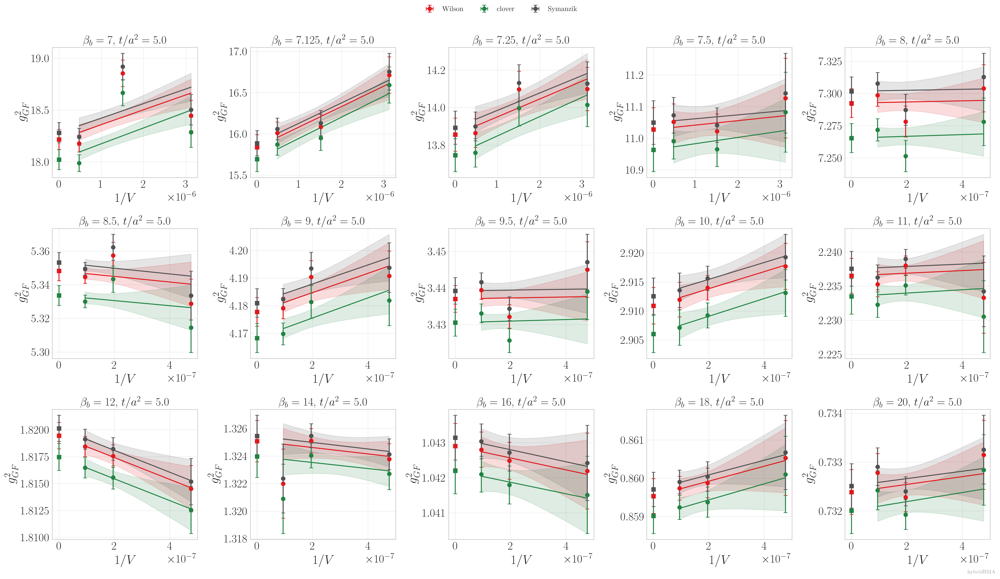

In [8]:
fig, axes = coupling_figure(IV_COUPLINGS)
for ax, coupling in zip(axes.ravel(), IV_COUPLINGS):
    times = sorted(bf.iv_fits[coupling]['g2'][FLOW][OBSERVABLES[0]], key=float)
    time = min(times, key=lambda t: abs(float(t) - CENTRAL_WINDOW[0]))
    for operator in OBSERVABLES:
        xfit, yfit, data = bf.infinite_volume_curve(coupling, FLOW, operator, time, x='g2')
        intercept = bf.infinite_volume.model.evaluate(0.0, bf.iv_fits[coupling]['g2'][FLOW][operator][time])
        color = OP_COLORS[operator]
        ax.errorbar(gv.mean(data.x), gv.mean(data.y), xerr=gv.sdev(data.x), yerr=gv.sdev(data.y),
                    fmt='o', capsize=3, color=color, label=OP_LABELS[operator])
        ax.plot(xfit, gv.mean(yfit), color=color)
        ax.fill_between(xfit, gv.mean(yfit)-gv.sdev(yfit), gv.mean(yfit)+gv.sdev(yfit), color=color, alpha=.15)
        ax.errorbar([0], [gv.mean(intercept)], yerr=[gv.sdev(intercept)], fmt='s', capsize=3, color=color)
    ax.set(title=rf'$\beta_b={beta_value(coupling):g}$, $t/a^2={time}$', xlabel=r'$1/V$', ylabel=r'$g^2_{GF}$')
for ax in axes.ravel()[len(IV_COUPLINGS):]:
    ax.set_visible(False)

handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc='upper center', frameon=False)
fig.tight_layout(rect=(0, 0, 1, .96))
base = OUTPUT_ROOT / f'infinite_volume_all_beta_{ANALYSIS_ID}'
add_fit_footer(fig)
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)

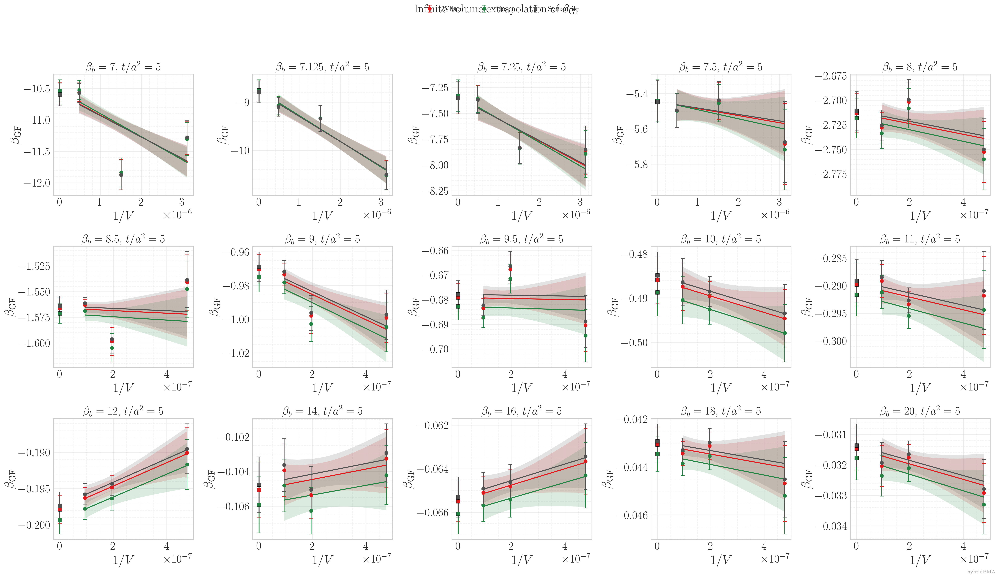

In [9]:
# Infinite-volume extrapolation: beta_GF versus 1/V

fig, axes = coupling_figure(IV_COUPLINGS)

for ax, coupling in zip(axes.ravel(), IV_COUPLINGS):
  available_times = sorted(
      bf.iv_fits[coupling]['beta'][FLOW][OBSERVABLES[0]],
      key=float,
  )
  time = min(
      available_times,
      key=lambda value: abs(float(value) - CENTRAL_WINDOW[0]),
  )

  for operator in OBSERVABLES:
      x_fit, beta_fit, beta_data = bf.infinite_volume_curve(
          coupling,
          FLOW,
          operator,
          time,
          x='beta',
      )

      x_fit = np.asarray(x_fit, dtype=float)
      beta_fit = np.asarray(beta_fit, dtype=object)
      beta_data_y = np.asarray(beta_data.y, dtype=object)

      color = OP_COLORS[operator]

      # Finite-volume beta_GF data.
      ax.errorbar(
          beta_data.x,
          gv.mean(beta_data_y),
          yerr=gv.sdev(beta_data_y),
          fmt='o',
          ms=5,
          capsize=3,
          elinewidth=1.0,
          color=color,
          label=OP_LABELS[operator],
          zorder=3,
      )

      # Infinite-volume extrapolation curve.
      ax.plot(
          x_fit,
          gv.mean(beta_fit),
          color=color,
          lw=1.6,
          zorder=2,
      )

      ax.fill_between(
          x_fit,
          gv.mean(beta_fit) - gv.sdev(beta_fit),
          gv.mean(beta_fit) + gv.sdev(beta_fit),
          color=color,
          alpha=0.16,
          linewidth=0,
          zorder=1,
      )

      # Infinite-volume intercept at 1/V = 0.
      beta_params = bf.iv_fits[coupling]['beta'][FLOW][operator][time]
      beta_infinite = bf.infinite_volume.model.evaluate(
          0.0,
          beta_params,
      )

      ax.errorbar(
          [0.0],
          [gv.mean(beta_infinite)],
          yerr=[gv.sdev(beta_infinite)],
          fmt='s',
          ms=6,
          capsize=3,
          color=color,
          markeredgecolor='black',
          markeredgewidth=0.4,
          zorder=4,
      )

  ax.set_title(
      rf'$\beta_b={beta_value(coupling):g}$, '
      rf'$t/a^2={float(time):g}$'
  )
  ax.set_xlabel(r'$1/V$')
  ax.set_ylabel(r'$\beta_{\mathrm{GF}}$')
  ax.minorticks_on()
  ax.grid(which='major', linestyle='-', alpha=0.35)
  ax.grid(which='minor', linestyle='--', alpha=0.20)

for ax in axes.ravel()[len(IV_COUPLINGS):]:
    ax.set_visible(False)

# Shared legend without duplicate entries.
handles, labels = axes.ravel()[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))

fig.legend(
  unique.values(),
  unique.keys(),
  ncol=len(OBSERVABLES),
  loc='upper center',
  frameon=False,
)

fig.suptitle(
  r'Infinite-volume extrapolation of $\beta_{\mathrm{GF}}$',
  y=0.995,
)

fig.tight_layout(rect=(0, 0, 1, 0.95))

output_base = OUTPUT_ROOT / f'infinite_volume_beta_vs_invV_{ANALYSIS_ID}'
add_fit_footer(fig)
fig.savefig(
  output_base.with_suffix('.png'),
  dpi=300,
  bbox_inches='tight',
)
fig.savefig(
  output_base.with_suffix('.pdf'),
  dpi=300,
  bbox_inches='tight',
)

plt.show()
plt.close(fig)


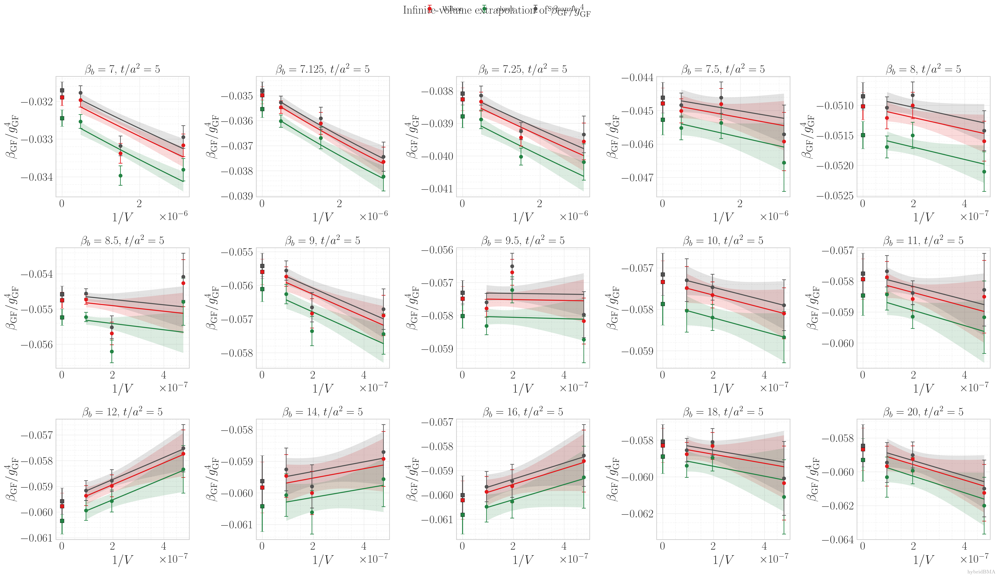

In [10]:
# Infinite-volume extrapolation:
# beta_GF / g_GF^4 versus 1/V

fig, axes = coupling_figure(IV_COUPLINGS)

for ax, coupling in zip(axes.ravel(), IV_COUPLINGS):
  available_times = sorted(
      bf.iv_fits[coupling]['beta'][FLOW][OBSERVABLES[0]],
      key=float,
  )
  time = min(
      available_times,
      key=lambda value: abs(float(value) - CENTRAL_WINDOW[0]),
  )

  for operator in OBSERVABLES:
      # Retrieve the beta_GF and g_GF^2 data used in the IV fits.
      _, _, beta_data = bf.infinite_volume_curve(
          coupling,
          FLOW,
          operator,
          time,
          x='beta',
      )
      _, _, g2_data = bf.infinite_volume_curve(
          coupling,
          FLOW,
          operator,
          time,
          x='g2',
      )

      # Confirm that beta and g^2 use the same volumes in the same order.
      if beta_data.labels != g2_data.labels:
          raise RuntimeError(
              f'Volume ordering mismatch for {coupling}, '
              f'{operator}, t/a^2={time}'
          )

      inv_volume = np.asarray(beta_data.x, dtype=float)
      beta_values = np.asarray(beta_data.y, dtype=object)
      g2_values = np.asarray(g2_data.y, dtype=object)

      # Since g2_values = g_GF^2, g_GF^4 = g2_values**2.
      ratio_data = beta_values / g2_values**2

      beta_params = bf.iv_fits[coupling]['beta'][FLOW][operator][time]
      g2_params = bf.iv_fits[coupling]['g2'][FLOW][operator][time]

      x_fit = np.linspace(
          float(np.min(inv_volume)),
          float(np.max(inv_volume)),
          300,
      )

      beta_fit = np.asarray(
          [
              bf.infinite_volume.model.evaluate(x, beta_params)
              for x in x_fit
          ],
          dtype=object,
      )
      g2_fit = np.asarray(
          [
              bf.infinite_volume.model.evaluate(x, g2_params)
              for x in x_fit
          ],
          dtype=object,
      )

      ratio_fit = beta_fit / g2_fit**2
      color = OP_COLORS[operator]

      # Finite-volume beta_GF/g_GF^4 data.
      ax.errorbar(
          inv_volume,
          gv.mean(ratio_data),
          yerr=gv.sdev(ratio_data),
          fmt='o',
          ms=5,
          capsize=3,
          elinewidth=1.0,
          color=color,
          label=OP_LABELS[operator],
          zorder=3,
      )

      # Ratio of the fitted beta_GF and g_GF^2 IV curves.
      ax.plot(
          x_fit,
          gv.mean(ratio_fit),
          color=color,
          lw=1.6,
          zorder=2,
      )

      ax.fill_between(
          x_fit,
          gv.mean(ratio_fit) - gv.sdev(ratio_fit),
          gv.mean(ratio_fit) + gv.sdev(ratio_fit),
          color=color,
          alpha=0.16,
          linewidth=0,
          zorder=1,
      )

      # Infinite-volume ratio at 1/V = 0.
      beta_infinite = bf.infinite_volume.model.evaluate(
          0.0,
          beta_params,
      )
      g2_infinite = bf.infinite_volume.model.evaluate(
          0.0,
          g2_params,
      )
      ratio_infinite = beta_infinite / g2_infinite**2

      ax.errorbar(
          [0.0],
          [gv.mean(ratio_infinite)],
          yerr=[gv.sdev(ratio_infinite)],
          fmt='s',
          ms=6,
          capsize=3,
          color=color,
          markeredgecolor='black',
          markeredgewidth=0.4,
          zorder=4,
      )

  ax.set_title(
      rf'$\beta_b={beta_value(coupling):g}$, '
      rf'$t/a^2={float(time):g}$'
  )
  ax.set_xlabel(r'$1/V$')
  ax.set_ylabel(r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$')
  ax.minorticks_on()
  ax.grid(which='major', linestyle='-', alpha=0.35)
  ax.grid(which='minor', linestyle='--', alpha=0.20)

for ax in axes.ravel()[len(IV_COUPLINGS):]:
    ax.set_visible(False)

# Shared legend without duplicate entries.
handles, labels = axes.ravel()[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))

fig.legend(
  unique.values(),
  unique.keys(),
  ncol=len(OBSERVABLES),
  loc='upper center',
  frameon=False,
)

fig.suptitle(
  r'Infinite-volume extrapolation of '
  r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$',
  y=0.995,
)

fig.tight_layout(rect=(0, 0, 1, 0.95))

output_base = (
  OUTPUT_ROOT
  / f'infinite_volume_beta_over_g4_vs_invV_{ANALYSIS_ID}'
)

add_fit_footer(fig)
fig.savefig(
  output_base.with_suffix('.png'),
  dpi=300,
  bbox_inches='tight',
)
fig.savefig(
  output_base.with_suffix('.pdf'),
  dpi=300,
  bbox_inches='tight',
)

plt.show()
plt.close(fig)


## Joint weak/strong interpolation and Bayesian model averaging

The candidate models below are fitted jointly to the shared infinite-volume posteriors.

For every flow-time window, one candidate model is fitted jointly to all retained flow times and all three discretizations. Bare couplings $\beta_b=20,\ldots,8$ determine the weak branch and the chirally extrapolated $\beta_b=7.5,7.25,7.125,7$ ensembles determine the strong branch. Thus the evidence is not formed by multiplying nominally independent evidences from correlated fits.

For $x=g^2_{\rm GF}$ and $u=x/(4\pi)$, the weak branch is either

$$
W(x)=\beta_{\rm PT}^{(3)}(x)\left[1+\sum_{k=1}^{N}c_k u^k\right]
$$

or the Fit 11 generalization $W(x)+a_0$. Above a matching point $x_m$ inside the measured gap, the strong branch is
The location is fitted globally across every flow time and operator as $x_m=x_8+f_{\rm match}(x_{7.5}-x_8)$, with $f_{\rm match}=0.2+0.6\,\Phi(q_{\rm match})$ and $q_{\rm match}\sim\mathcal N(0,1)$. This induces the proper prior $f_{\rm match}\sim\mathrm{Uniform}(0.2,0.8)$.

$$
\beta(x)=W(x)+x^2 z^{q}\frac{\sum_{i=0}^{m}a_i z^i}{\prod_{j=1}^{n}(1+z/\rho_j)},
\qquad z=\frac{x-x_m}{\Delta x},\qquad 0<\rho_1<\cdots<\rho_n,
$$

with $q=2$ for a $C^1$ match. A denominator of order $n$ is parameterized as $\prod_{j=1}^{n}(1+z/\rho_j)$ with ordered $\rho_j>0$, so all Padé poles lie at negative $z$, outside the physical strong branch, without a pole-label degeneracy. Proper, common-scale priors are mandatory because marginal likelihoods are otherwise undefined. Their widths and prior-predictive implications must be varied as a sensitivity analysis before quoting final model probabilities.


In [ ]:
from betafn import (
    HybridInterpolationCandidate,
    default_hybrid_candidates,
    fit_hybrid_bma_candidates,
    hybrid_match_fraction,
    hybrid_parameter_records,
    model_average_predictions,
    relative_partial_uncertainty_percent,
    run_hybrid_bma_window,
)

progress_start('joint hybrid interpolation and evidence')
if HYBRID_EXPLICIT_MODELS is None:
    HYBRID_CANDIDATES = default_hybrid_candidates(
        weak_orders_by_family=HYBRID_WEAK_ORDERS_BY_FAMILY,
        pade_orders=HYBRID_PADE_ORDERS,
        match_fractions=HYBRID_MATCH_FRACTIONS,
        match_bounds=HYBRID_MATCH_BOUNDS,
        continuities=HYBRID_CONTINUITIES,
    )
else:
    HYBRID_CANDIDATES = tuple(
        HybridInterpolationCandidate(**selection)
        for selection in HYBRID_EXPLICIT_MODELS
    )

if not HYBRID_CANDIDATES:
    raise ValueError('Select at least one hybrid BMA candidate')
if len({candidate.name for candidate in HYBRID_CANDIDATES}) != len(HYBRID_CANDIDATES):
    raise ValueError('The selected hybrid BMA candidates contain duplicates')

hybrid_model_selection = pd.DataFrame([
    {'model': candidate.name, **candidate.metadata()}
    for candidate in HYBRID_CANDIDATES
])
hybrid_model_selection['model_prior_probability'] = 1.0 / len(HYBRID_CANDIDATES)
display(hybrid_model_selection)
print(f'Selected {len(HYBRID_CANDIDATES)} hybrid models.')

# HYBRID_OUTPUT_ROOT was defined in the main configuration cell so shared
# preprocessing and hybrid outputs cannot be split across misleading paths.

hybrid_interpolations = {}
for window in WINDOWS:
    print(
        'hybrid interpolation:', window,
        len(HYBRID_CANDIDATES), 'joint candidate models',
    )
    hybrid_interpolations[window] = fit_hybrid_bma_candidates(
        bf, window, FLOW, OBSERVABLES,
        weak_couplings=WEAK_COUPLINGS,
        strong_couplings=STRONG_COUPLINGS,
        candidates=HYBRID_CANDIDATES,
        max_workers=HYBRID_MAX_WORKERS,
        checkpoint_dir=(
            HYBRID_CHECKPOINT_ROOT / window_tag(window)
        ),
        **HYBRID_PRIOR_WIDTHS,
    )

evidence_rows = []
for window, result in hybrid_interpolations.items():
    for name, candidate_fit in result.candidate_fits.items():
        evidence_rows.append({
            'window': window_tag(window), 'model': name,
            'log_evidence': candidate_fit.log_evidence,
            'posterior_model_probability': result.weights[name],
            **candidate_fit.candidate.metadata(),
        })
hybrid_evidence = pd.DataFrame(evidence_rows)
hybrid_evidence.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_model_evidence.csv', index=False
)
display(
    hybrid_evidence.sort_values(
        'posterior_model_probability', ascending=False
    ).head(20)
)

# Complete fitted-coefficient ledger, including evidence and posterior
# model probability for every candidate and flow-time window.
hybrid_coefficient_table = pd.DataFrame([
    row
    for result in hybrid_interpolations.values()
    for row in hybrid_parameter_records(result)
])
hybrid_coefficient_table.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_fitted_coefficients.csv', index=False
)
coefficient_text_path = HYBRID_OUTPUT_ROOT / 'hybrid_fitted_coefficients.txt'
with coefficient_text_path.open('w') as stream:
    for (window, model), rows in hybrid_coefficient_table.groupby(
        ['window', 'model'], sort=False
    ):
        first = rows.iloc[0]
        stream.write(
            f'Window {window}\nModel {model}\n'
            f'log evidence = {first.log_evidence:.10g}\n'
            f'model probability = {first.model_probability:.10g}\n'
        )
        stream.write(rows[[
            'operator', 'flow_time', 'parameter', 'mean', 'sdev'
        ]].to_string(
            index=False,
            formatters={
                'flow_time': lambda value: f'{value:g}',
                'mean': lambda value: f'{value:.10g}',
                'sdev': lambda value: f'{value:.6g}',
            },
        ))
        stream.write('\n\n')
print(
    f'Saved {len(hybrid_coefficient_table)} coefficient rows to',
    coefficient_text_path,
)
progress_done('joint hybrid interpolation and evidence')


,model,weak_family,weak_order,pade_order,match_fraction,continuity,model_prior_probability
0,fit4_o4__pade_3_2__match_0p25__C1,fit4,4,[3/2],0.25,C1,0.083333
1,fit4_o4__pade_3_2__match_0p50__C1,fit4,4,[3/2],0.50,C1,0.083333
2,fit4_o4__pade_3_2__match_0p75__C1,fit4,4,[3/2],0.75,C1,0.083333
3,fit4_o4__pade_2_1__match_0p25__C1,fit4,4,[2/1],0.25,C1,0.083333
4,fit4_o4__pade_2_1__match_0p50__C1,fit4,4,[2/1],0.50,C1,0.083333
5,fit4_o4__pade_2_1__match_0p75__C1,fit4,4,[2/1],0.75,C1,0.083333
6,fit11_o4__pade_3_2__match_0p25__C1,fit11,4,[3/2],0.25,C1,0.083333
7,fit11_o4__pade_3_2__match_0p50__C1,fit11,4,[3/2],0.50,C1,0.083333
8,fit11_o4__pade_3_2__match_0p75__C1,fit11,4,[3/2],0.75,C1,0.083333
9,fit11_o4__pade_2_1__match_0p25__C1,fit11,4,[2/1],0.25,C1,0.083333


Selected 12 hybrid models.
hybrid interpolation: (5.0, 6.0) 12 joint candidate models


/Users/yaman/jupyter-env/lib/python3.13/site-packages/gvar/__init__.py:953: UserWarning: Negative eigenvalue with |lambda/lambda_max| = 5e-12 > svdcut; need larger svdcut?
  gflat, i_wgts, i_invwgts = svd(gflat, svdcut=svdcut, noise=noise, wgts=True)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/gvar/__init__.py:953: UserWarning: Negative eigenvalue with |lambda/lambda_max| = 4.8e-12 > svdcut; need larger svdcut?
  gflat, i_wgts, i_invwgts = svd(gflat, svdcut=svdcut, noise=noise, wgts=True)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/gvar/__init__.py:953: UserWarning: Negative eigenvalue with |lambda/lambda_max| = 4.6e-12 > svdcut; need larger svdcut?
  gflat, i_wgts, i_invwgts = svd(gflat, svdcut=svdcut, noise=noise, wgts=True)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/gvar/__init__.py:953: UserWarning: Negative eigenvalue with |lambda/lambda_max| = 4.5e-12 > svdcut; need larger svdcut?
  gflat, i_wgts, i_invwgts = svd(gflat, svdcut=svdcut, noise=noise, w

### Model-averaged interpolation curves

The band is formed from the law of total covariance. It contains both the posterior covariance inside each candidate and the variation of candidate means. The raw points retain their full $g^2$--$\beta$ correlation in the joint evidence fit.


In [ ]:
progress_start('candidate and model-averaged interpolation plots')
central_interpolation = hybrid_interpolations[CENTRAL_WINDOW]

# Evidence weights are available before any continuum extrapolation.
weight_table = pd.DataFrame({
    'model': list(central_interpolation.weights),
    'weight': list(central_interpolation.weights.values()),
}).sort_values('weight', ascending=False)
displayed = weight_table.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(displayed.model, displayed.weight, color='0.35')
ax.set_xlabel('posterior model probability')
ax.set_ylabel('complete weak/strong interpolation model')
ax.set_title('Largest Bayesian model weights')
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_model_weights'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)

# One diagnostic figure per weak-family/order, Pade order, matching
# fraction, and operator. C1/C2 alternatives are overlaid on that figure.
candidate_groups = {}
for name, candidate_fit in central_interpolation.candidate_fits.items():
    candidate = candidate_fit.candidate
    group_key = (
        candidate.weak_family, candidate.weak_order,
        candidate.numerator_order, candidate.denominator_order,
        candidate.match_fraction,
        candidate.match_lower, candidate.match_upper,
    )
    candidate_groups.setdefault(group_key, []).append((name, candidate_fit))

continuity_colors = {1: 'tab:blue', 2: 'tab:orange'}
continuity_styles = {1: '-', 2: '--'}
candidate_plot_jobs = [
    (group_key, variants, operator)
    for group_key, variants in candidate_groups.items()
    for operator in OBSERVABLES
]
for plot_index, (group_key, variants, operator) in enumerate(
    candidate_plot_jobs, start=1
):
    variants = sorted(variants, key=lambda item: item[1].candidate.continuity)
    reference_candidate = variants[0][1]
    keys = sorted(
        [key for key in reference_candidate.targets
         if key[0] == FLOW and key[1] == operator],
        key=lambda key: float(key[2]),
    )
    selected_indices = sorted(set((0, len(keys) // 2, len(keys) - 1)))
    fig, axes = plt.subplots(
        1, len(selected_indices), figsize=(6 * len(selected_indices), 5),
        squeeze=False, sharey=True,
    )
    for ax, selected_index in zip(axes.ravel(), selected_indices):
        key = keys[selected_index]
        target = reference_candidate.targets[key]
        xmin, xmax = min(gv.mean(target.x)), max(gv.mean(target.x))
        xgrid = np.linspace(xmin, xmax, 240)
        ax.errorbar(
            gv.mean(target.x), gv.mean(target.y),
            xerr=gv.sdev(target.x), yerr=gv.sdev(target.y),
            fmt='o', ms=4, capsize=2, color='black', alpha=.70,
            label='infinite-volume data',
        )
        for name, candidate_fit in variants:
            continuity = candidate_fit.candidate.continuity
            prediction = np.asarray(
                betafn.fitting.hybrid.evaluate_hybrid_target(
                    candidate_fit, bf, key, xgrid
                ), dtype=object,
            )
            mean, sdev = gv.mean(prediction), gv.sdev(prediction)
            color = continuity_colors.get(continuity, f'C{continuity % 10}')
            fitted_fraction = hybrid_match_fraction(candidate_fit)
            label = (
                f'C{continuity}; '
                f'f={gv.mean(fitted_fraction):.3f}({gv.sdev(fitted_fraction):.3f}); '
                f'P={central_interpolation.weights[name]:.3f}'
            )
            ax.plot(
                xgrid, mean, color=color,
                ls=continuity_styles.get(continuity, '-'), label=label,
            )
            ax.fill_between(
                xgrid, mean-sdev, mean+sdev, color=color, alpha=.14,
            )
        ax.set_title(rf'$t/a^2={float(key[2]):g}$')
        ax.set_xlabel(r'$g^2_{\rm GF}$')
    axes.ravel()[0].set_ylabel(r'$\beta_{\rm GF}$')
    axes.ravel()[0].legend(frameon=False, fontsize=10)
    (family, order, numerator, denominator, fraction,
     match_lower, match_upper) = group_key
    fig.suptitle(
        f'{OP_LABELS[operator]}: {family} order {order}, '
        f'Pade [{numerator}/{denominator}], '
        + (
            f'match fitted in [{match_lower:.2f}, {match_upper:.2f}]'
            if fraction is None else f'match={fraction:.2f}'
        )
    )
    fig.tight_layout(rect=(0, 0, 1, .94))
    fraction_tag = (
        (f'fitted_{match_lower:.2f}_{match_upper:.2f}'.replace('.', 'p'))
        if fraction is None
        else f'{fraction:.2f}'.replace('.', 'p')
    )
    base = HYBRID_OUTPUT_ROOT / (
        f'hybrid_candidate_interpolation_{family}_o{order}_'
        f'pade_{numerator}_{denominator}_match_{fraction_tag}_{operator}'
    )
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
    print(
        f'[candidate plot {plot_index}/{len(candidate_plot_jobs)}] '
        f'{base.name}',
        flush=True,
    )

reference_fit = next(iter(central_interpolation.candidate_fits.values()))
for operator in OBSERVABLES:
    keys = sorted(
        [key for key in reference_fit.targets if key[0] == FLOW and key[1] == operator],
        key=lambda key: float(key[2]),
    )
    selected_indices = sorted(set((0, len(keys) // 2, len(keys) - 1)))
    fig, ax = plt.subplots(figsize=(8, 6))
    colors = plt.cm.viridis(np.linspace(.12, .88, len(selected_indices)))
    for color, selected_index in zip(colors, selected_indices):
        key = keys[selected_index]
        target = reference_fit.targets[key]
        xmin, xmax = min(gv.mean(target.x)), max(gv.mean(target.x))
        xgrid = np.linspace(xmin, xmax, 240)
        predictions = {
            name: np.asarray(
                betafn.fitting.hybrid.evaluate_hybrid_target(
                    fit, bf, key, xgrid
                ), dtype=object,
            )
            for name, fit in central_interpolation.candidate_fits.items()
        }
        average = model_average_predictions(predictions, central_interpolation.weights)
        ax.plot(xgrid, average.mean, color=color, label=rf'$t/a^2={float(key[2]):g}$')
        sigma = np.sqrt(np.clip(np.diag(average.covariance), 0.0, None))
        ax.fill_between(xgrid, average.mean - sigma, average.mean + sigma, color=color, alpha=.18)
        ax.errorbar(
            gv.mean(target.x), gv.mean(target.y),
            xerr=gv.sdev(target.x), yerr=gv.sdev(target.y),
            fmt='o', ms=4, capsize=2, color=color, alpha=.75,
        )
    ax.set_xlabel(r'$g^2_{\rm GF}$'); ax.set_ylabel(r'$\beta_{\rm GF}$')
    ax.set_title(f'{OP_LABELS[operator]}: joint weak/strong BMA interpolation')
    ax.legend(frameon=False)
    fig.tight_layout()
    base = HYBRID_OUTPUT_ROOT / f'hybrid_bma_interpolation_{operator}'
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
progress_done('candidate and model-averaged interpolation plots')

### Continuum extrapolation of the inspected interpolation posteriors

This stage reuses the candidate posteriors and evidence weights plotted above. It performs no new interpolation fits. Correlated and diagonal continuum fits are evaluated separately for every complete candidate before model averaging.


In [ ]:
progress_start('candidate-wise continuum extrapolation')
hybrid_results = {}
hybrid_grid = np.round(
    np.arange(G2_GRID[0], G2_GRID[1] + 0.5 * G2_GRID[2], G2_GRID[2]),
    10,
)
for window in WINDOWS:
    interpolation_result = hybrid_interpolations[window]
    print('continuum extrapolation:', window, 'correlated')
    hybrid_results[(window, 'correlated')] = run_hybrid_bma_window(
        bf, window, FLOW, OBSERVABLES,
        weak_couplings=WEAK_COUPLINGS,
        strong_couplings=STRONG_COUPLINGS,
        g2_grid=hybrid_grid,
        candidates=HYBRID_CANDIDATES,
        cov_mode='empirical', tau0=config.tau0,
        prefit_candidate_fits=interpolation_result.candidate_fits,
        **HYBRID_PRIOR_WIDTHS,
    )
    print('continuum extrapolation:', window, 'diagonal')
    hybrid_results[(window, 'diagonal')] = run_hybrid_bma_window(
        bf, window, FLOW, OBSERVABLES,
        weak_couplings=WEAK_COUPLINGS,
        strong_couplings=STRONG_COUPLINGS,
        g2_grid=hybrid_grid,
        candidates=HYBRID_CANDIDATES,
        cov_mode='diagonal', tau0=config.tau0,
        prefit_candidate_fits=interpolation_result.candidate_fits,
        **HYBRID_PRIOR_WIDTHS,
    )
progress_done('candidate-wise continuum extrapolation')


In [ ]:
progress_start('model-averaged continuum summary plots')
central = hybrid_results[(CENTRAL_WINDOW, 'correlated')]

# Final BMA continuum beta function and beta/g^4.
for divide_by_g4, stem, ylabel in (
    (False, 'hybrid_bma_continuum_beta_vs_g2', r'$\beta_{\rm GF}$'),
    (True, 'hybrid_bma_continuum_beta_over_g4_vs_g2', r'$\beta_{\rm GF}/g_{\rm GF}^4$'),
):
    fig, ax = plt.subplots(figsize=(8, 6))
    for operator in OBSERVABLES:
        average = central.averages[operator]
        x = central.model_variance_by_choice[operator]['g2']
        y = average.prediction / x**2 if divide_by_g4 else average.prediction
        ax.plot(x, gv.mean(y), color=OP_COLORS[operator], label=OP_LABELS[operator])
        ax.fill_between(
            x, gv.mean(y) - gv.sdev(y), gv.mean(y) + gv.sdev(y),
            color=OP_COLORS[operator], alpha=.18,
        )
    ax.axvline(G2_T0, color='black', ls='--', lw=1.2, label=r'$g^2_{\rm GF}(t_0)$')
    ax.set_xlabel(r'$g^2_{\rm GF}$'); ax.set_ylabel(ylabel)
    if divide_by_g4:
        ax.set_ylim(-.065, -.035)
    ax.legend(frameon=False)
    fig.tight_layout()
    base = HYBRID_OUTPUT_ROOT / stem
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
progress_done('model-averaged continuum summary plots')


### Full interpolation-model error budget for $\beta(g^2)$

The within-model covariance is the propagated statistical component. The between-model covariance is allocated among weak family, weak order, Padé order, matching location, and matching smoothness using Shapley effects. This allocation includes interactions and sums to the total interpolation-model variance. Continuum-window and covariance-treatment sensitivities are shown separately. Chiral-ansatz and infinite-volume-ansatz systematics are not estimated by this interpolation ensemble; their statistical uncertainties are already propagated, while their model-form systematics require explicit alternative chiral and volume models before a numerical percentage is defensible.


In [ ]:
progress_start('hybrid beta-function error budget')
central = hybrid_results[(CENTRAL_WINDOW, 'correlated')]
diagonal = hybrid_results[(CENTRAL_WINDOW, 'diagonal')]
error_rows = []
for operator in OBSERVABLES:
    average = central.averages[operator]
    x = central.model_variance_by_choice[operator]['g2']
    diagonal_average = diagonal.averages[operator]
    statistical_variance = np.diag(average.within_covariance)
    components = central.model_variance_by_choice[operator]
    covariance_variance = (diagonal_average.mean - average.mean) ** 2

    window_means = []
    for window in WINDOWS:
        result = hybrid_results[(window, 'correlated')]
        candidate_x = result.model_variance_by_choice[operator]['g2']
        mapping = {round(float(g), 12): value for g, value in zip(candidate_x, result.averages[operator].mean)}
        window_means.append(mapping)

    for index, g2 in enumerate(x):
        key = round(float(g2), 12)
        available_window_values = [values[key] for values in window_means if key in values]
        window_variance = (
            float(np.var(available_window_values, ddof=0))
            if len(available_window_values) > 1 else np.nan
        )
        model_component_variances = {
            axis: float(values[index])
            for axis, values in components.items() if axis != 'g2'
        }
        total_variance = float(statistical_variance[index]) + sum(model_component_variances.values())
        total_variance += float(covariance_variance[index])
        if np.isfinite(window_variance):
            total_variance += window_variance
        mean = float(average.mean[index])
        row = {
            'operator': operator, 'g2': float(g2), 'beta_mean': mean,
            'statistical_percent': float(relative_partial_uncertainty_percent(statistical_variance[index], mean)),
            'continuum_covariance_percent': float(relative_partial_uncertainty_percent(covariance_variance[index], mean)),
            'continuum_window_percent': (
                float(relative_partial_uncertainty_percent(window_variance, mean))
                if np.isfinite(window_variance) else np.nan
            ),
            'chiral_model_percent': np.nan,
            'infinite_volume_model_percent': np.nan,
            'total_available_percent': float(relative_partial_uncertainty_percent(total_variance, mean)),
        }
        for axis, variance in model_component_variances.items():
            row[f'interpolation_{axis}_percent'] = float(
                relative_partial_uncertainty_percent(variance, mean)
            )
        error_rows.append(row)

hybrid_beta_error_budget = pd.DataFrame(error_rows)
hybrid_beta_error_budget.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_beta_error_budget.csv', index=False
)
component_columns = [
    column for column in hybrid_beta_error_budget
    if column.endswith('_percent')
    and column not in ('total_available_percent',)
    and hybrid_beta_error_budget[column].notna().any()
]
fig, axes = plt.subplots(1, len(OBSERVABLES), figsize=(17, 5), sharey=True)
for ax, operator in zip(np.atleast_1d(axes), OBSERVABLES):
    rows = hybrid_beta_error_budget.query('operator == @operator')
    for column in component_columns:
        ax.plot(rows.g2, rows[column], lw=1.2, label=column.replace('_percent', '').replace('_', ' '))
    ax.plot(rows.g2, rows.total_available_percent, color='black', lw=2.2, label='total available')
    ax.set_title(OP_LABELS[operator]); ax.set_xlabel(r'$g^2_{\rm GF}$'); ax.set_yscale('log')
axes[0].set_ylabel(r'partial relative uncertainty [\%]')
axes[-1].legend(frameon=False, fontsize=8)
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_beta_error_budget'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
display(hybrid_beta_error_budget)
progress_done('hybrid beta-function error budget')


### Bruno--Sommer continuum goodness of fit

For every candidate continuum fit, the ordinary least-squares statistic is retained. In addition, the generalized expectation and $p$-value are calculated from the actual covariance $C$ and the covariance used for weighting. With model Jacobian $J$, weight square root $W$, and $P=WJ(J^T W^2J)^{-1}J^TW$, the null distribution is

$$
\chi^2 \sim \sum_k \lambda_k z_k^2,
\qquad
\{\lambda_k\}=\operatorname{eig}\!\left[C^{1/2}W(1-P)WC^{1/2}\right].
$$

This calibrates goodness of fit for diagonal or regularized weights. It neither estimates the covariance nor replaces statistical/model-systematic propagation.


In [ ]:
progress_start('generalized continuum goodness of fit')
gof_rows = []
for (window, mode), result in hybrid_results.items():
    for model, by_operator in result.continuum_quality.items():
        for operator, entries in by_operator.items():
            for g2, entry in zip(result.g2, entries):
                if entry is None:
                    continue
                gof_rows.append({
                    'window': window_tag(window), 'mode': mode,
                    'model': model, 'model_weight': result.weights[model],
                    'operator': operator, 'g2': float(g2), **entry,
                })
hybrid_continuum_gof = pd.DataFrame(gof_rows)
hybrid_continuum_gof.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_continuum_generalized_gof.csv', index=False
)
display(hybrid_continuum_gof.head())
progress_done('generalized continuum goodness of fit')


### Model-averaged continuum extrapolation panels

Filled points are the model-averaged interpolated values entering the continuum fit. Each line and band averages the complete candidate continuum extrapolations, so the model indicator is shared across all displayed $a^2/t$ values rather than independently redrawn point by point.


In [ ]:
progress_start('continuum extrapolation diagnostic plots')
central = hybrid_results[(CENTRAL_WINDOW, 'correlated')]
targets_to_plot = tuple(g for g in TARGET_G2 if central.g2[0] <= g <= central.g2[-1])
fig, axes = plt.subplots(2, 4, figsize=(18, 9), squeeze=False)
for ax, requested_g2 in zip(axes.ravel(), targets_to_plot):
    grid_index = int(np.argmin(np.abs(central.g2 - requested_g2)))
    g2 = float(central.g2[grid_index])
    for operator in OBSERVABLES:
        candidate_lines = {}
        candidate_points = {}
        xline = None
        for name, candidate_fit in central.candidate_fits.items():
            params = central.continuum_parameters[name][operator][grid_index]
            if params is None:
                continue
            keys = sorted(
                [key for key in candidate_fit.targets
                 if key[0] == FLOW and key[1] == operator
                 and CENTRAL_WINDOW[0] <= float(key[2]) <= CENTRAL_WINDOW[1]
                 and min(gv.mean(candidate_fit.targets[key].x)) <= g2
                 <= max(gv.mean(candidate_fit.targets[key].x))],
                key=lambda key: float(key[2]),
            )
            measured = np.asarray([float(key[2]) for key in keys])
            nominal = measured - config.tau0
            xdata = 1.0 / nominal
            if xline is None:
                xline = np.linspace(0.0, 1.05 * max(xdata), 200)
            candidate_lines[name] = params['beta'][0] + params['slope'][0] * xline
            candidate_points[name] = np.asarray([
                (tn / tm) * np.asarray(
                    betafn.fitting.hybrid.evaluate_hybrid_target(
                        candidate_fit, bf, key, g2
                    ), dtype=object,
                ).item()
                for key, tm, tn in zip(keys, measured, nominal)
            ], dtype=object)
        if set(candidate_lines) != set(central.weights):
            continue
        line_average = model_average_predictions(candidate_lines, central.weights)
        point_average = model_average_predictions(candidate_points, central.weights)
        ax.plot(xline, line_average.mean, color=OP_COLORS[operator], lw=1.5)
        line_sigma = np.sqrt(np.clip(np.diag(line_average.covariance), 0.0, None))
        ax.fill_between(
            xline, line_average.mean-line_sigma, line_average.mean+line_sigma,
            color=OP_COLORS[operator], alpha=.16,
        )
        ax.errorbar(
            xdata, point_average.mean,
            yerr=np.sqrt(np.clip(np.diag(point_average.covariance), 0.0, None)),
            fmt='o', ms=4, capsize=2, color=OP_COLORS[operator],
            label=OP_LABELS[operator],
        )
    ax.text(.04, .94, rf'$g^2_{{\rm GF}}={g2:g}$', transform=ax.transAxes, va='top')
    ax.set_xlabel(r'$a^2/t$')
axes.ravel()[0].legend(frameon=False)
fig.supylabel(r'$\beta_{\rm GF}$')
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_bma_continuum_a2_over_t_beta'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
progress_done('continuum extrapolation diagnostic plots')


### Blinded $\Lambda$ parameter from the complete model mixture

The nonlinear $\Lambda$ integral is evaluated separately for every complete weak/strong candidate. Only then are the candidate $\Lambda$ posteriors model averaged. This avoids applying a nonlinear integral to a Gaussian moment match of the beta-function mixture. The reported GF-scheme result is blinded by the same repository-external factor used elsewhere.


In [ ]:
progress_start('blinded Lambda analysis')
from betafn.blinding import add_blinded_watermark, blind_lambda_estimate
from betafn.weak_coupling import constrained_smooth_match, lambda_parameter_from_smooth_beta

central = hybrid_results[(CENTRAL_WINDOW, 'correlated')]
hybrid_lambda_rows = []
for operator in OBSERVABLES:
    lambda_by_model = {}
    for name in central.candidate_fits:
        raw_values = central.continuum_by_model[name][operator]
        valid = np.asarray([value is not None for value in raw_values], dtype=bool)
        x = central.g2[valid]
        beta = np.asarray(raw_values, dtype=object)[valid]
        ratio = beta / x**2
        if x[-1] < G2_T0 - 1e-10:
            raise RuntimeError(f'{name}, {operator}: continuum curve does not reach g^2(t0)')
        smooth = constrained_smooth_match(
            x, ratio, pt_over_g4,
            match_window=(max(float(x[0]), .9), 1.2),
            correction_powers=(3, 4),
        )
        estimate = lambda_parameter_from_smooth_beta(
            x, ratio, smooth, bf.perturbative_beta_function,
            reference_g2=G2_T0,
        )
        lambda_by_model[name] = np.asarray([estimate['lambda_gf_over_mu']], dtype=object)
    lambda_average = model_average_predictions(lambda_by_model, central.weights)
    lambda_gf = lambda_average.prediction[0]
    report = {
        'lambda_gf_over_mu': {
            'central': float(gv.mean(lambda_gf)),
            'plus_sigma': float(gv.mean(lambda_gf) + gv.sdev(lambda_gf)),
            'minus_sigma': float(gv.mean(lambda_gf) - gv.sdev(lambda_gf)),
        },
        'lambda_msbar_over_mu': {},
        'lambda_msbar_over_lambda_gf': float(bf.perturbative_beta_function.lambda_msbar_over_lambda_gf),
    }
    report['lambda_msbar_over_mu'] = {
        label: report['lambda_msbar_over_lambda_gf'] * value
        for label, value in report['lambda_gf_over_mu'].items()
    }
    blinded = blind_lambda_estimate(report)
    values = blinded['lambda_gf_over_mu']
    hybrid_lambda_rows.append({
        'operator': operator, 'operator_label': OP_LABELS[operator],
        'g2_reference': G2_T0, 'lambda_values_blinded': True,
        'sqrt8t0_lambda_GF_central': values['central'],
        'sqrt8t0_lambda_GF_low': min(values['plus_sigma'], values['minus_sigma']),
        'sqrt8t0_lambda_GF_high': max(values['plus_sigma'], values['minus_sigma']),
        'within_model_variance': float(lambda_average.within_covariance[0, 0]),
        'between_model_variance': float(lambda_average.between_covariance[0, 0]),
    })

hybrid_lambda_table = pd.DataFrame(hybrid_lambda_rows)
hybrid_lambda_table.to_csv(HYBRID_OUTPUT_ROOT / 'hybrid_bma_lambda_blinded.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
for index, row in hybrid_lambda_table.iterrows():
    center = row.sqrt8t0_lambda_GF_central
    ax.errorbar(
        index, center,
        yerr=[[center-row.sqrt8t0_lambda_GF_low], [row.sqrt8t0_lambda_GF_high-center]],
        fmt='o', capsize=4, color=OP_COLORS[row.operator], label=row.operator_label,
    )
ax.set_xticks(range(len(hybrid_lambda_table)), hybrid_lambda_table.operator_label)
ax.set_ylabel(r'$\sqrt{8t_0}\,\Lambda_{\rm GF}$')
ax.set_title('BLINDED hybrid-BMA result')
add_blinded_watermark(fig)
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_bma_lambda_blinded'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
display(hybrid_lambda_table)
progress_done('blinded Lambda analysis')


### Optional hybrid flow-time thinning study

This repeats the complete joint interpolation, evidence calculation, continuum extrapolation, and model average after selecting a boundary-anchored flow-time grid. It is disabled by default because it multiplies the number of expensive joint candidate fits. Set `RUN_HYBRID_THINNING = True` to run spacings $\Delta(t/a^2)=0.1,0.2,0.3$.


In [ ]:
progress_start('optional hybrid thinning study')
hybrid_thinning_results = {}
if RUN_HYBRID_THINNING:
    hybrid_grid = np.round(
        np.arange(G2_GRID[0], G2_GRID[1] + 0.5 * G2_GRID[2], G2_GRID[2]), 10
    )
    for spacing in HYBRID_THINNING_SPACINGS:
        for window in WINDOWS:
            key = (float(spacing), window)
            print('hybrid thinning:', spacing, window)
            hybrid_thinning_results[key] = run_hybrid_bma_window(
                bf, window, FLOW, OBSERVABLES,
                weak_couplings=WEAK_COUPLINGS,
                strong_couplings=STRONG_COUPLINGS,
                g2_grid=hybrid_grid,
                candidates=HYBRID_CANDIDATES,
                cov_mode='empirical', tau0=config.tau0,
                flow_time_spacing=spacing,
                max_workers=HYBRID_MAX_WORKERS,
                checkpoint_dir=(
                    HYBRID_CHECKPOINT_ROOT
                    / f'dt_{float(spacing):.2f}'.replace('.', 'p')
                    / window_tag(window)
                ),
                **HYBRID_PRIOR_WIDTHS,
            )
    thinning_rows = []
    for (spacing, window), result in hybrid_thinning_results.items():
        for operator, average in result.averages.items():
            x = result.model_variance_by_choice[operator]['g2']
            for g2, mean, variance in zip(x, average.mean, np.diag(average.covariance)):
                thinning_rows.append({
                    'spacing': spacing, 'window': window_tag(window),
                    'operator': operator, 'g2': float(g2),
                    'beta_mean': float(mean), 'beta_sdev': float(np.sqrt(max(variance, 0.0))),
                })
    pd.DataFrame(thinning_rows).to_csv(
        HYBRID_OUTPUT_ROOT / 'hybrid_thinning_continuum.csv', index=False
    )
else:
    print('Hybrid thinning disabled.')
progress_done('optional hybrid thinning study')
